# UR3e 机器人功率（PC）数据集：特征分析与相关性研究

本 Notebook 针对 `data/UR3e_train.csv`（116 条轨迹 / 105,400 个时序样本）做系统性的特征分析，为后续功率建模（ARIMAX / LightGBM / Transformer）提供依据。

**输出变量**：`PC = V × I`（机器人总功率，W）

**输入特征（25 维）**

| 类别 | 变量 | 含义 |
|---|---|---|
| 关节位置 | `q1`–`q6` | 6 个关节角度 |
| 关节速度 | `dq1`–`dq6` | 6 个关节角速度 |
| 关节力矩 | `T1`–`T6` | 6 个关节力矩 |
| 末端力 | `Fx, Fy, Fz` | 基坐标系下 TCP 处的力 |
| 末端力矩 | `Fa1, Fa2, Fa3` | 基坐标系下 TCP 处的力矩 |
| 动量 | `M` | 笛卡尔线动量范数 |

**分析框架**

1. **单变量分布分析**：偏度 / 峰度 / 离群率 / 输出分布形态 / 轨迹间与轨迹内方差分解
2. **线性相关性分析**：Pearson & Spearman、共线性诊断（强相关对 + VIF）、线性回归基线
3. **非线性关系探究**：分箱均值曲线、互信息、距离相关、单特征 GBDT、偏依赖（PDP）与二维交互
4. **时延相关性分析**：分组互相关 CCF、峰位识别、采样率稳健性、滞后特征对建模的实际增益

> 所有统计均按 `trajectory_id` 分组处理，避免把不同轨迹首尾相接产生虚假的跳变相关。

In [1]:
# ============================================================
# 0. 环境准备与数据加载
# ============================================================
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# 注意：plt.style.use / sns.set_style 会重置字体族，中文字体必须在其之后设置
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_style("whitegrid")

# ---- 统一图幅：A4 版心宽度 15.8 cm，300 dpi，字号 9–10.5 pt ----
DPI = 300
TEXT_W_CM = 15.8
FIG_W = TEXT_W_CM / 2.54          # ≈ 6.22 in

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams.update({
    "font.size": 10,             # 基准字号
    "axes.titlesize": 10.5,      # 子图标题
    "axes.labelsize": 10,        # 坐标轴标题
    "xtick.labelsize": 9,        # 刻度标签
    "ytick.labelsize": 9,
    "legend.fontsize": 9,        # 图例
    "legend.title_fontsize": 9,
    "figure.titlesize": 10.5,
    "figure.dpi": DPI,           # 屏幕显示与位图导出统一 300 dpi
    "savefig.dpi": DPI,
    "figure.figsize": (FIG_W, FIG_W * 0.5),
    "savefig.bbox": "tight",
})
FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND = 9, 10, 10.5, 9


def fig_size(h_ratio=0.5):
    """按 A4 版心取图幅：宽度固定 15.8 cm，高度 = 宽度 × h_ratio。"""
    return (FIG_W, FIG_W * h_ratio)


def tag_title(ax, tag, text="", fontsize=FS_TITLE, pad=4):
    """分图编号：居中标题「(a) 说明」；全文不再使用「图 N」式编号。"""
    ax.set_title(f"({tag}) {text}".strip(), loc="center", fontsize=fontsize, pad=pad)


FIG_DIR = os.path.join("figures", "feature_analysis")
os.makedirs(FIG_DIR, exist_ok=True)


def savefig(fig, name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    print(f"[saved] {path}  ({DPI} dpi)")
    return path


train_df = pd.read_csv(r"data\UR3e_train.csv")

Q_COLS = [f"q{i}" for i in range(1, 7)]
DQ_COLS = [f"dq{i}" for i in range(1, 7)]
T_COLS = [f"T{i}" for i in range(1, 7)]
F_COLS = ["Fx", "Fy", "Fz", "Fa1", "Fa2", "Fa3"]
FEATS = Q_COLS + DQ_COLS + T_COLS + F_COLS + ["M"]  # 25 维输入
TARGET = "PC"

# 采样间隔 / 采样率（时延分析需要把 lag 换算成秒）
train_df["dt"] = train_df.groupby("trajectory_id")["t1"].diff()
train_df["fs"] = (1.0 / train_df.groupby("trajectory_id")["dt"].transform("median")).round(0)

df = train_df  # 后续统一使用 df

print("数据形状:", df.shape)
print(f"输入特征数: {len(FEATS)}")
print("输入特征:", FEATS)
print("输出变量:", TARGET)
print(f"图幅: 宽 {TEXT_W_CM} cm（A4 版心）× 高度按需 | 分辨率 {DPI} dpi")

数据形状: (105400, 52)
输入特征数: 25
输入特征: ['q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'dq1', 'dq2', 'dq3', 'dq4', 'dq5', 'dq6', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'Fx', 'Fy', 'Fz', 'Fa1', 'Fa2', 'Fa3', 'M']
输出变量: PC
图幅: 宽 15.8 cm（A4 版心）× 高度按需 | 分辨率 300 dpi


## 0. 数据概览

先确认数据的完整性、采样率构成、以及输出变量与原始电压/电流的关系。这一步决定后续怎么划分数据、时延要不要换算成秒。

In [2]:
# ============================================================
# 0.1 数据概览：轨迹 / 采样率 / 缺失 / PC 与 V、I 的关系
# ============================================================
n_traj = df.trajectory_id.nunique()
raw_cols = [c for c in df.columns if c not in ("dt", "fs")]
print(f"样本数 {len(df)} | 轨迹数 {n_traj} | 原始列缺失值 {df[raw_cols].isna().sum().sum()} "
      f"| 完全重复行 {df.duplicated().sum()}")

fs_cnt = df.groupby("trajectory_id")["fs"].first().value_counts().sort_index()
print("\n按轨迹统计的采样率分布:")
print(fs_cnt.rename_axis("采样率(Hz)").to_frame("轨迹数"))

traj_stat = (
    df.groupby("trajectory_id")
    .agg(
        点数=("t1", "size"),
        时长s=("t1", lambda s: s.max() - s.min()),
        PC均值=("PC", "mean"),
        PC标准差=("PC", "std"),
        PC最大=("PC", "max"),
    )
)
print("\n各轨迹统计（describe）:")
display(traj_stat.describe().round(3))

# PC 是否等于 V*I，以及 PC 与 I、V 的关系
print(f"max|V*I - PC| = {(df.V * df.I - df.PC).abs().max():.3e}")
print(f"corr(PC, I) = {df.PC.corr(df.I):.6f}")
print(f"corr(PC, V) = {df.PC.corr(df.V):.6f}")
print(f"V 的变异系数 = {df.V.std() / df.V.mean() * 100:.3f} %")
print("→ 母线电压近似恒压，PC 本质上是电流 I 的线性缩放，两者的相关分析结论几乎等价")

样本数 105400 | 轨迹数 116 | 原始列缺失值 0 | 完全重复行 0

按轨迹统计的采样率分布:
         轨迹数
采样率(Hz)     
2.0        2
50.0      32
100.0     82

各轨迹统计（describe）:


,点数,时长s,PC均值,PC标准差,PC最大
count,116.000,116.000,116.000,116.000,116.000
mean,908.621,16.520,44.009,5.753,60.456
std,677.665,19.235,7.091,6.633,21.653
min,200.000,5.068,38.055,1.672,43.478
25%,500.000,5.088,38.978,2.021,45.933
50%,500.000,5.361,42.110,3.124,53.037
75%,2000.000,40.221,45.508,6.388,63.334
max,2000.000,100.302,69.979,33.594,142.500


max|V*I - PC| = 2.842e-14
corr(PC, I) = 0.999998
corr(PC, V) = 0.239978
V 的变异系数 = 0.049 %
→ 母线电压近似恒压，PC 本质上是电流 I 的线性缩放，两者的相关分析结论几乎等价


## 1. 单变量分布分析

关注四个问题：
- 特征分布是否重尾/偏斜（影响标准化、损失函数选择）；
- 是否存在大量静止态样本（`dq ≈ 0` 的零值堆积）；
- 输出 `PC` 是否正态（决定误差指标与置信区间）；
- 轨迹之间（任务/负载差异）与轨迹内部（运动过程）的方差各占多少。

In [3]:
# ============================================================
# 1.1 单变量描述统计（偏度 / 峰度 / 离散度 / 零值 / 离群率）
# ============================================================
cols = FEATS + [TARGET]


def outlier_rate(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100


desc = pd.DataFrame(index=cols)
desc["均值"] = df[cols].mean()
desc["标准差"] = df[cols].std()
desc["最小值"] = df[cols].min()
desc["Q25"] = df[cols].quantile(0.25)
desc["中位数"] = df[cols].median()
desc["Q75"] = df[cols].quantile(0.75)
desc["最大值"] = df[cols].max()
desc["IQR"] = desc["Q75"] - desc["Q25"]
desc["偏度"] = df[cols].skew()
desc["超峰度"] = df[cols].kurt()
desc["变异系数"] = (desc["标准差"] / desc["均值"].abs()).replace([np.inf, -np.inf], np.nan)
desc["零值比例%"] = (df[cols].abs() < 1e-9).mean() * 100
desc["离群率%"] = df[cols].apply(outlier_rate)

desc.round(4).to_csv(os.path.join(FIG_DIR, "univariate_stats.csv"), encoding="utf-8-sig")
display(desc.round(4))
print("说明：dq 系列均值接近 0，变异系数无意义；离群率按 1.5×IQR 规则统计")

,均值,标准差,最小值,Q25,中位数,Q75,最大值,IQR,偏度,超峰度,变异系数,零值比例%,离群率%
q1,-0.0102,1.1312,-2.0251,-0.8089,-0.0251,0.8249,1.9749,1.6338,0.1371,-0.7869,111.1457,0.0000,0.0000
q2,-1.6454,0.6085,-2.9122,-1.9694,-1.6125,-1.3235,-0.3130,0.6459,0.0696,-0.4570,0.3698,0.0000,1.2742
q3,0.2062,0.6871,-1.0266,-0.2411,0.0000,0.7281,2.1463,0.9692,0.2684,-0.7388,3.3321,0.0000,0.0000
q4,-0.4880,1.0916,-2.9491,-0.4182,-0.0264,0.0982,0.7737,0.5164,-1.5480,0.8864,2.2370,0.0000,16.1290
q5,1.0420,1.2056,-1.7515,1.1557,1.5548,1.6849,2.3445,0.5292,-1.5999,0.9778,1.1570,0.0000,16.1290
q6,1.8245,4.4405,-0.9780,-0.2789,-0.0000,0.2157,12.4570,0.4946,1.8226,1.3585,2.4339,0.0000,16.1290
dq1,0.0013,0.4870,-2.4028,-0.1641,0.0000,0.1592,2.4319,0.3233,0.0536,7.1026,376.2965,18.2761,10.4934
dq2,0.0011,0.5583,-2.3482,-0.2431,0.0000,0.2467,2.3304,0.4897,-0.0045,2.5696,506.3923,15.0882,9.1509
dq3,-0.0001,0.5560,-2.3393,-0.2749,0.0000,0.2750,2.3263,0.5499,-0.0046,1.4986,3844.2140,14.8491,7.2789
dq4,0.0014,0.3741,-2.3306,-0.1483,0.0000,0.1520,2.3321,0.3003,-0.0297,5.2092,261.5231,16.5446,10.4326


说明：dq 系列均值接近 0，变异系数无意义；离群率按 1.5×IQR 规则统计


[saved] figures\feature_analysis\01_univariate_hist.png  (300 dpi)


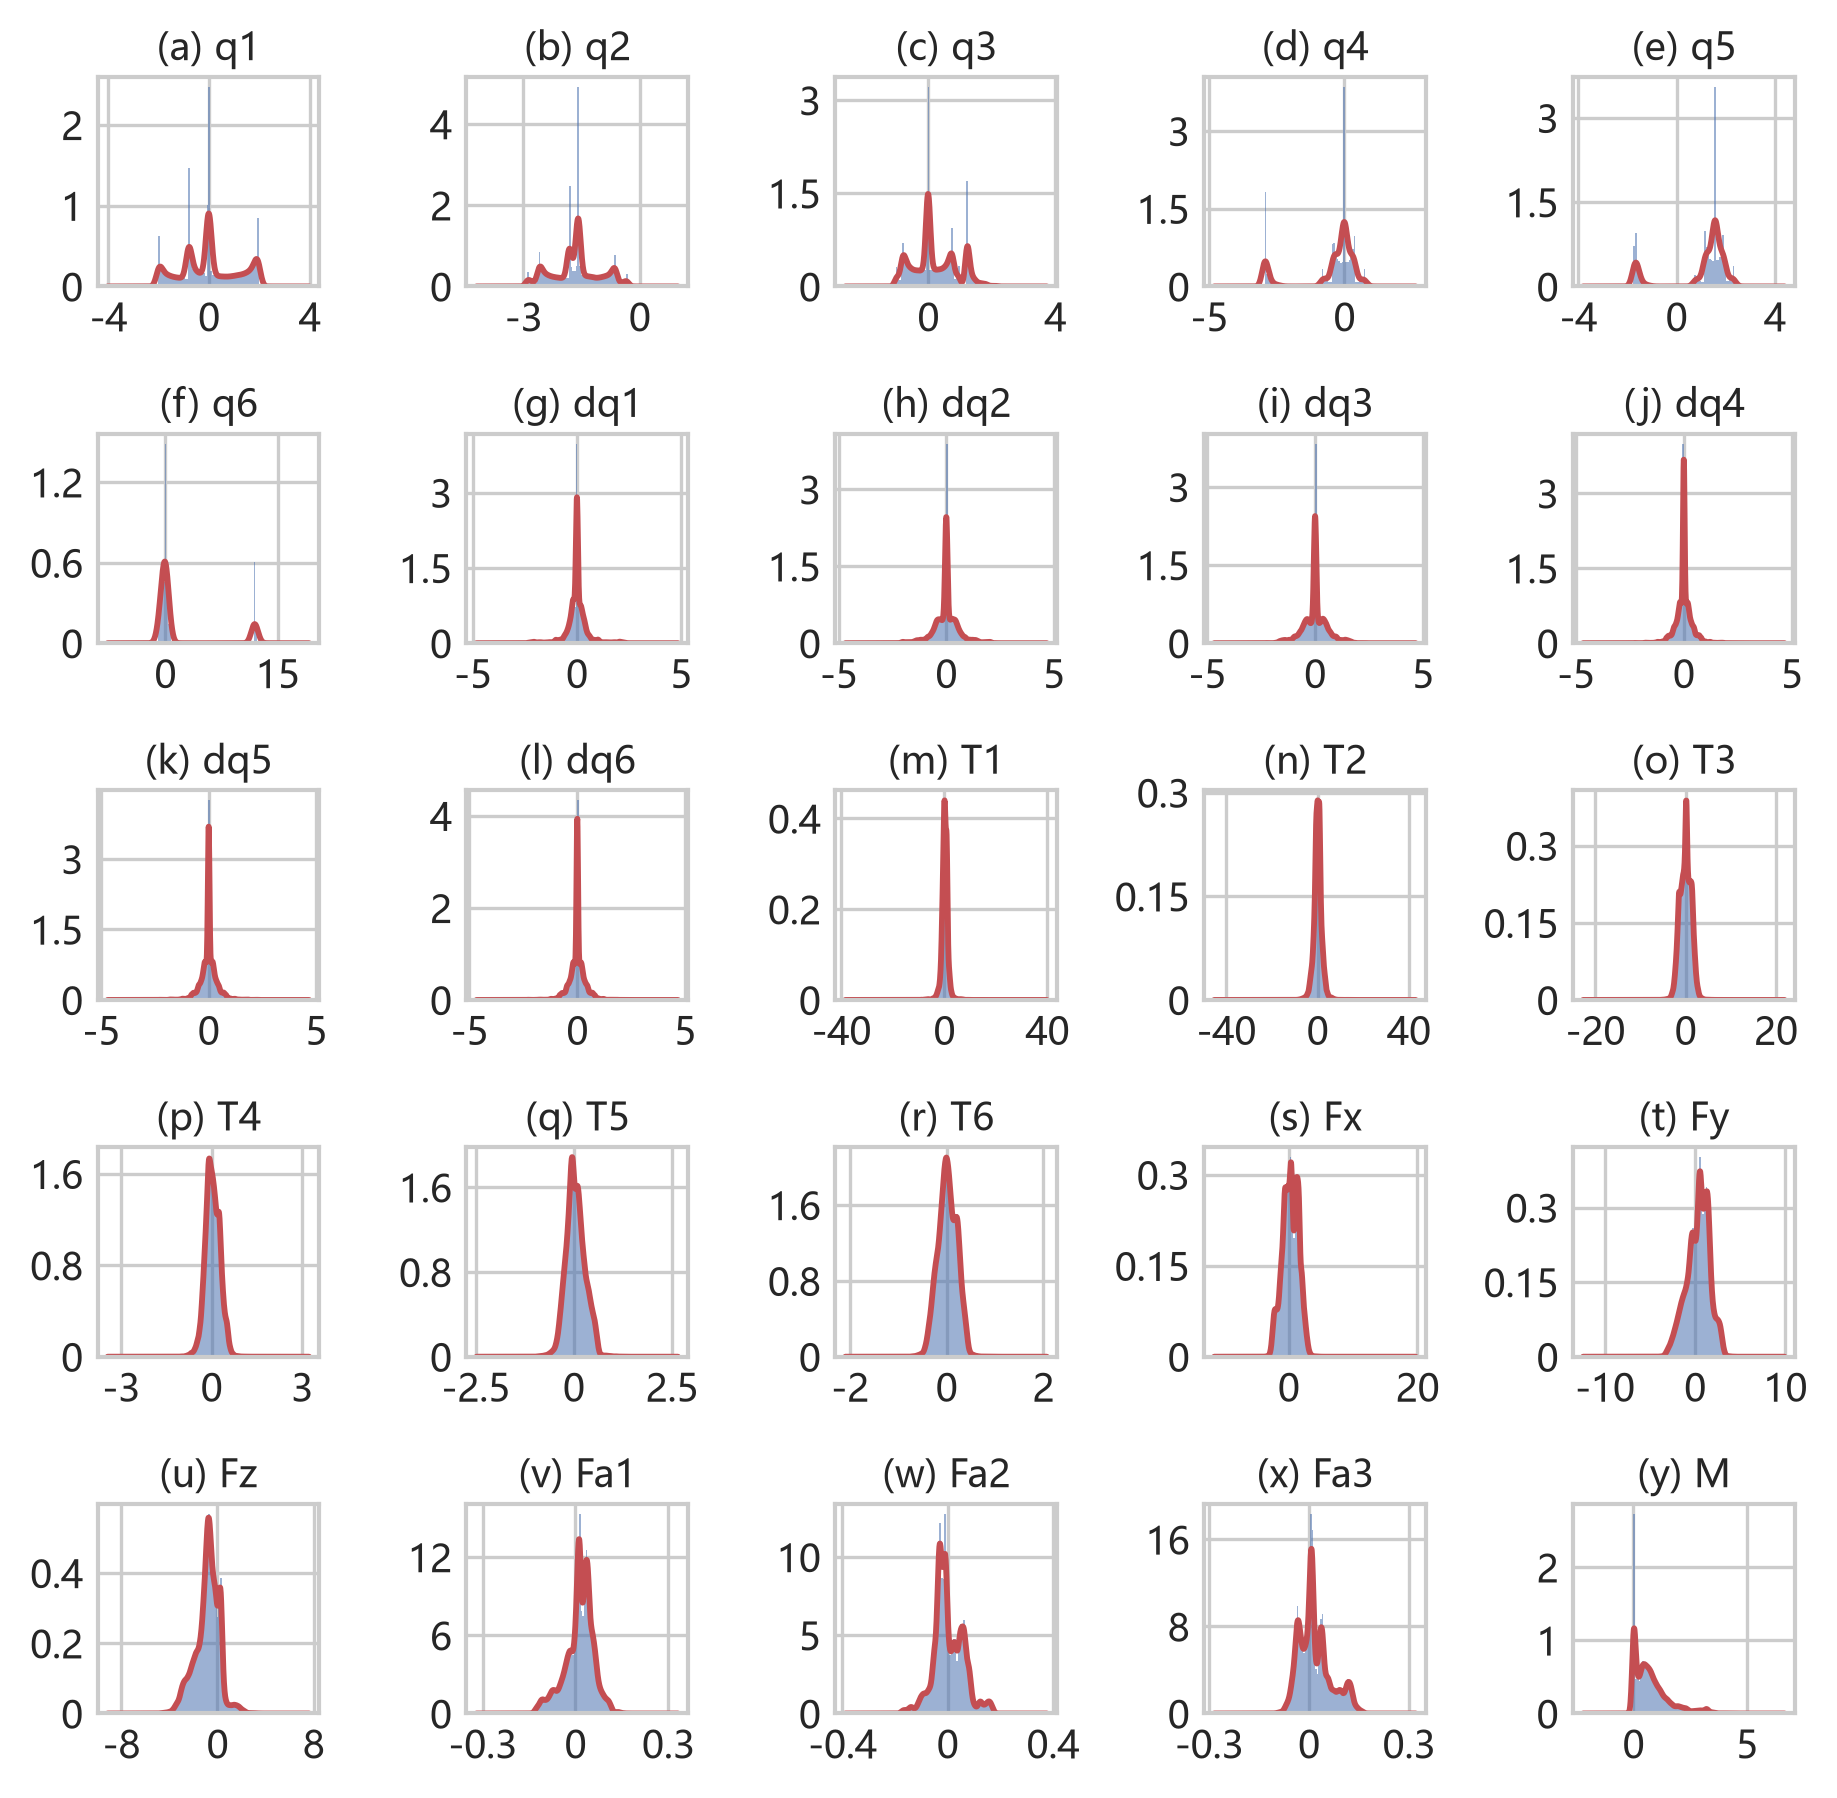

In [4]:
# 25 个输入特征的边缘分布（直方图 + KDE）；分图编号 (a)–(y)
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

ALPHA25 = "abcdefghijklmnopqrstuvwxy"   # a..y 共 25 个字母

fig, axes = plt.subplots(5, 5, figsize=fig_size(0.98))
for ax, c, tag in zip(axes.ravel(), FEATS, ALPHA25):
    ax.hist(df[c], bins=60, density=True, color="#4C72B0", alpha=0.55, edgecolor="none")
    df[c].plot(kind="kde", ax=ax, color="#C44E52", lw=1.4)
    tag_title(ax, tag, c, fontsize=FS_TICK)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.tick_params(labelsize=FS_TICK)
    # 3 cm 宽的面板里只放 2 个刻度，并用紧凑数字格式，避免标签相互重叠
    ax.xaxis.set_major_locator(MaxNLocator(2))
    ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
fig.tight_layout()
savefig(fig, "01_univariate_hist")
plt.show()

[saved] figures\feature_analysis\02a_pc_hist.png  (300 dpi)


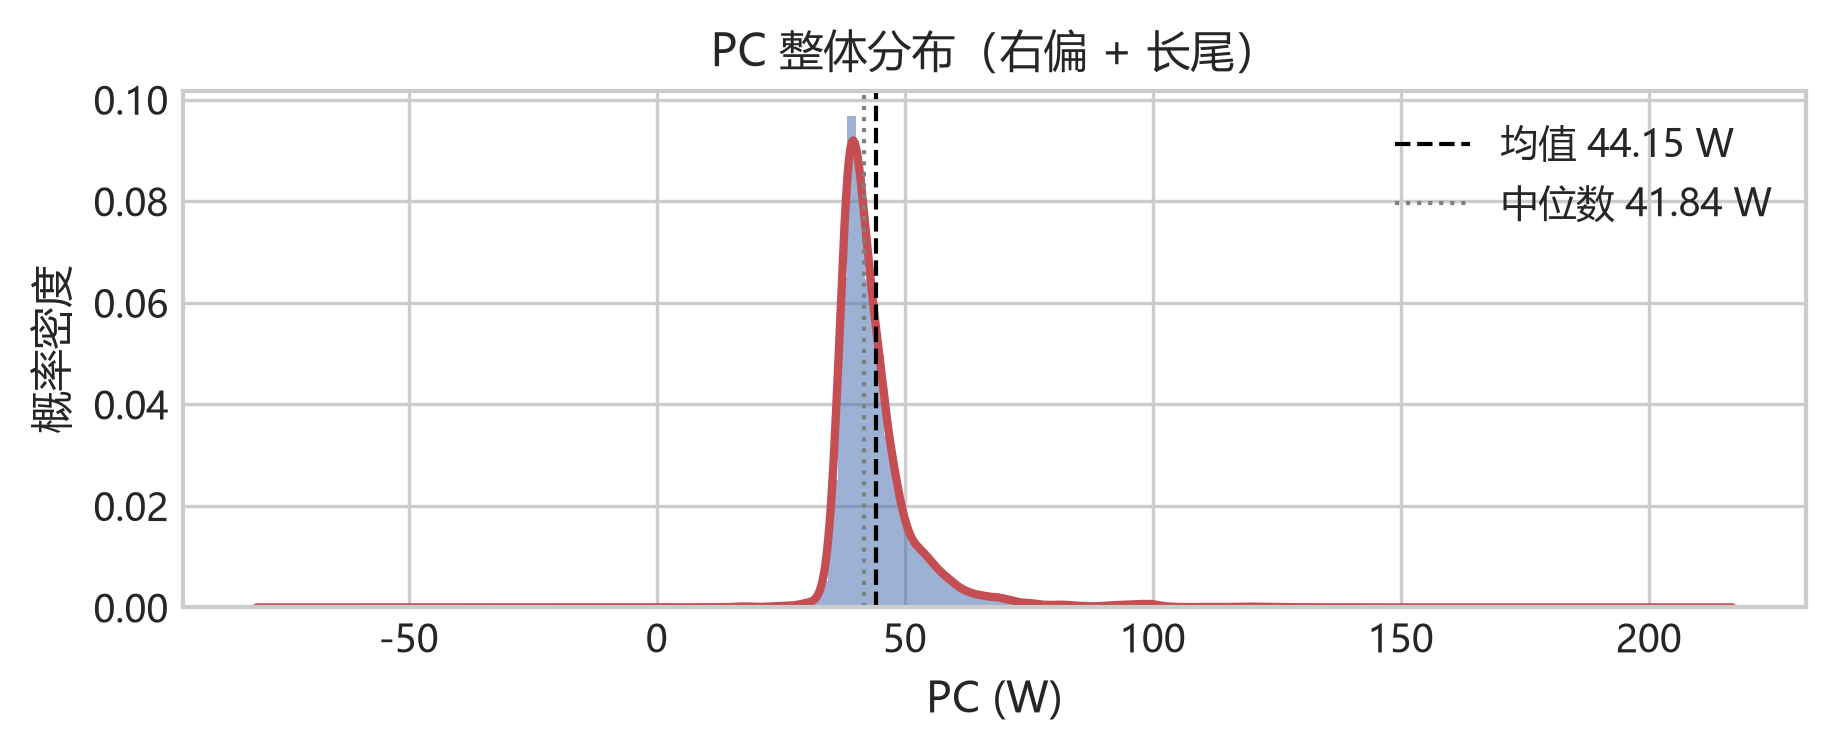

[saved] figures\feature_analysis\02b_pc_qq.png  (300 dpi)


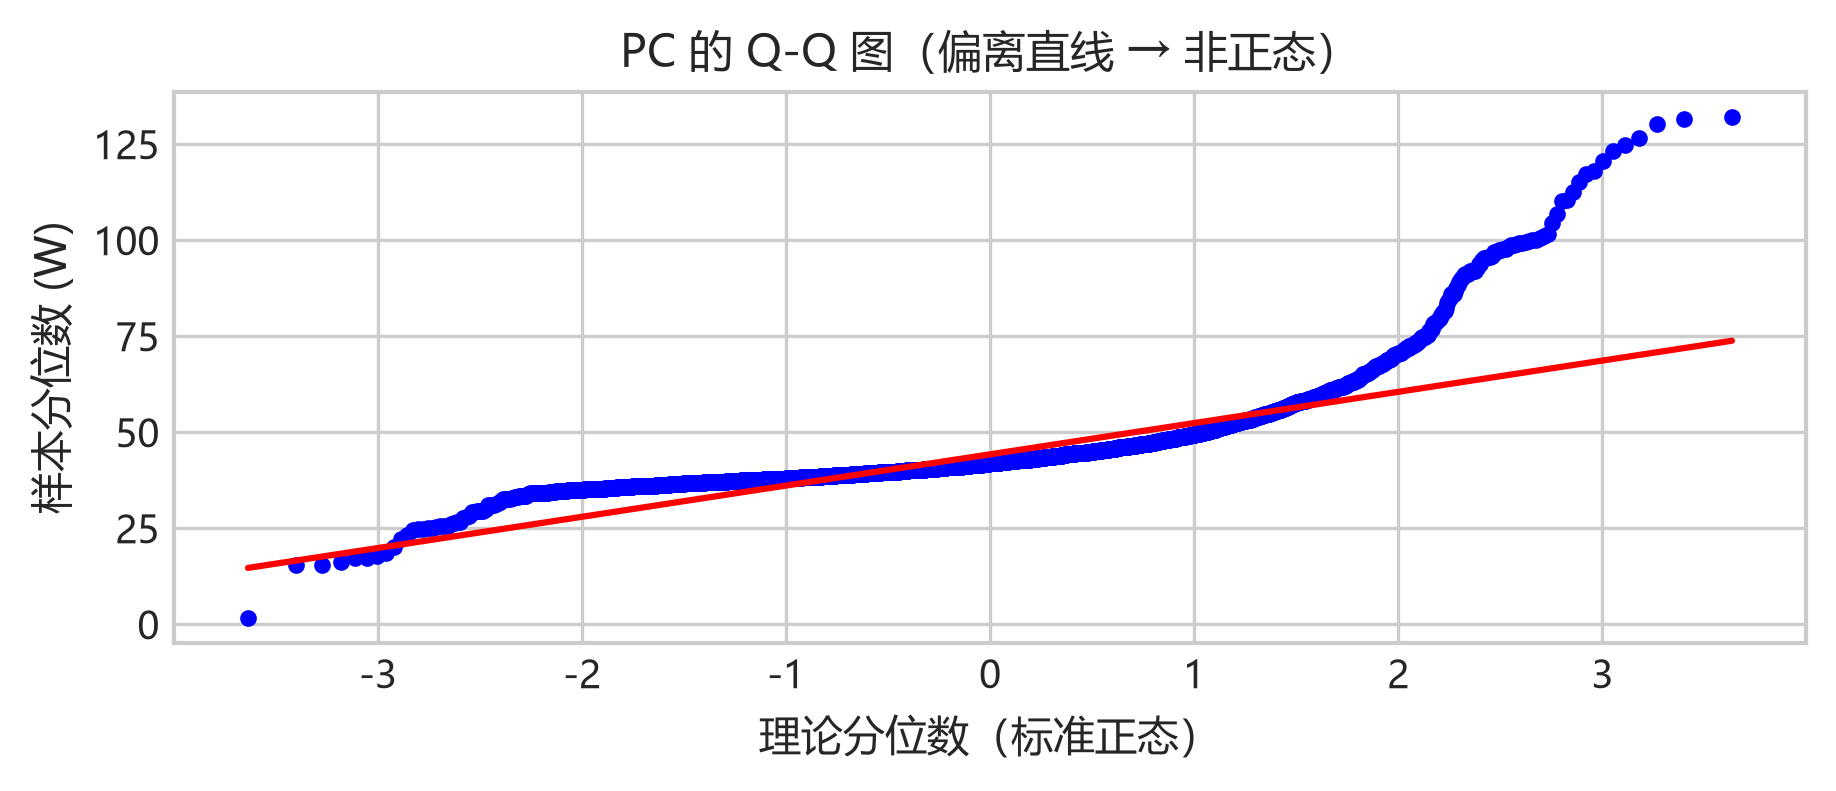

[saved] figures\feature_analysis\02c_traj_mean.png  (300 dpi)


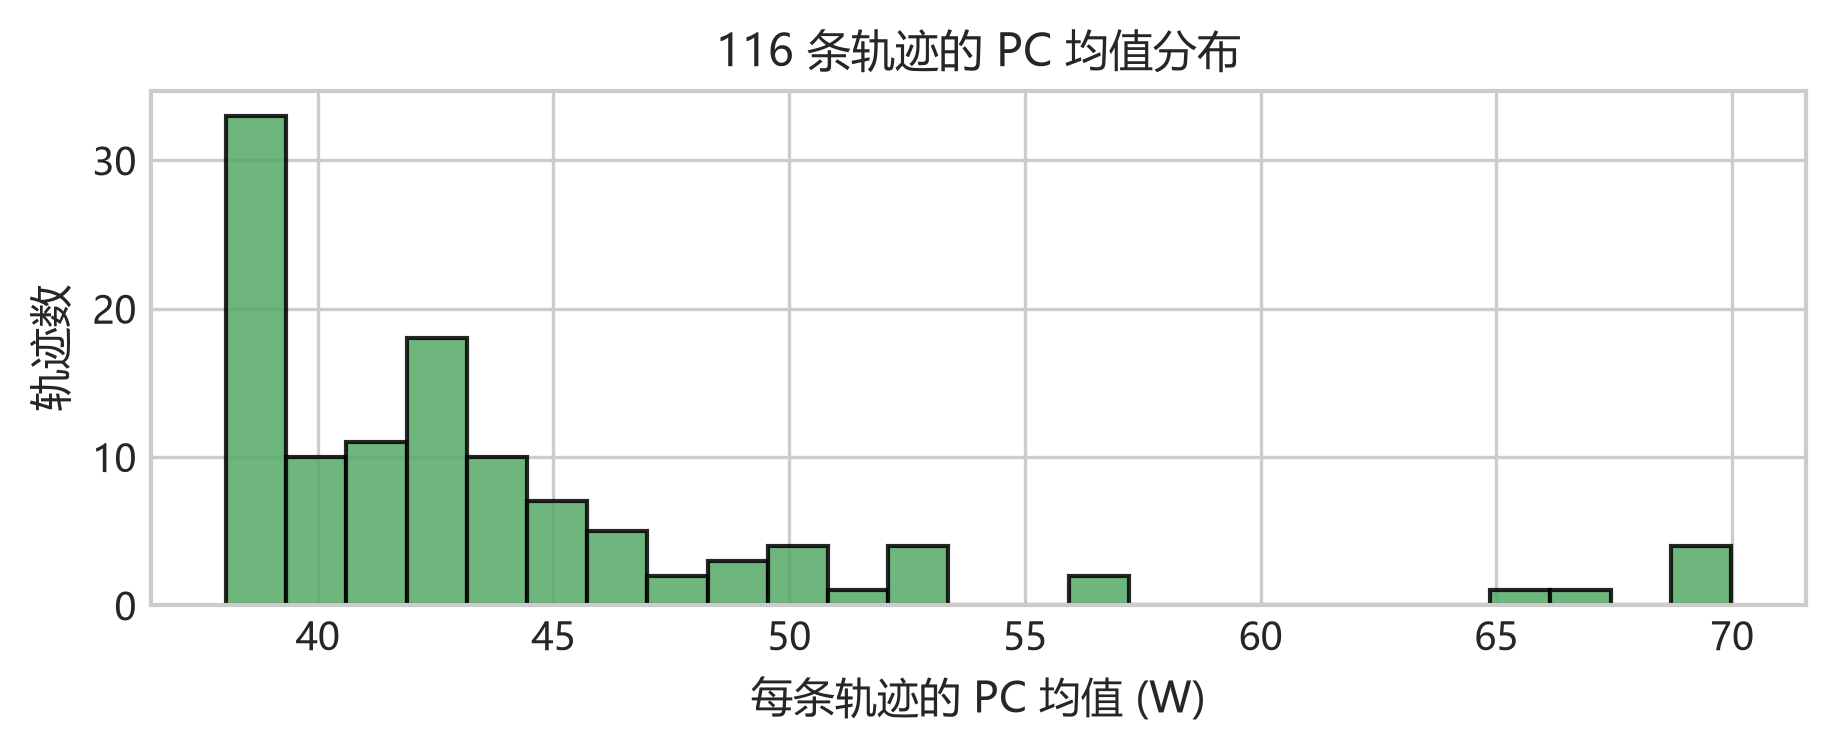

[saved] figures\feature_analysis\02d_traj_box.png  (300 dpi)


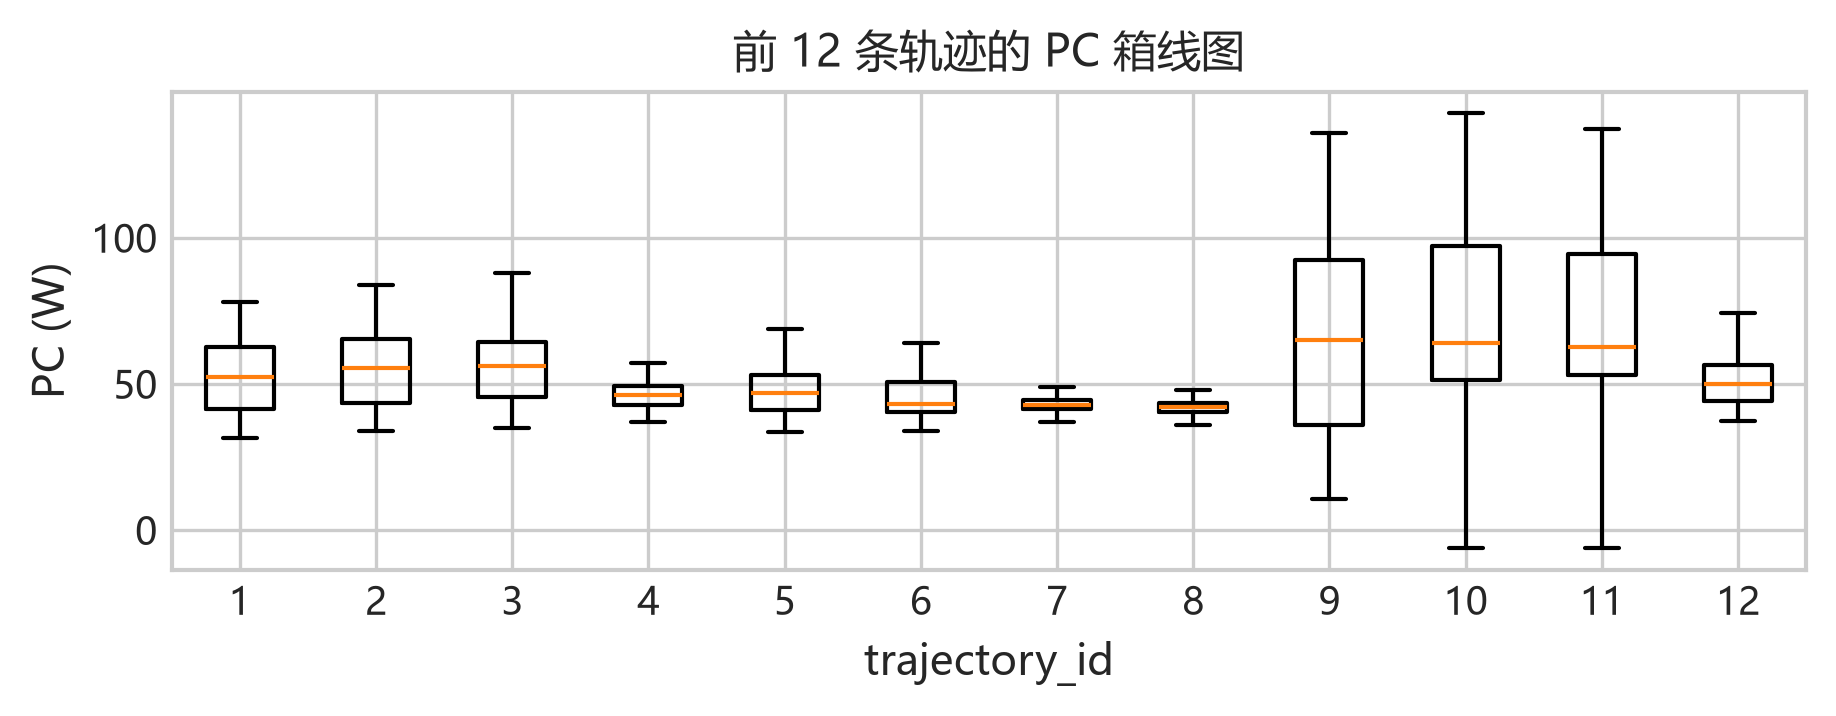

PC < 0 比例: 0.014%   （减速回馈/再生制动，极少数）
PC > 100 W 比例: 0.394%   （高功率尖峰，长尾来源）
偏度 3.288 | 超峰度 17.813
方差分解: 轨迹间方差 32.036 W² | 总方差 88.577 W² | ICC=0.362
组内去均值后 PC 标准差: 7.519 W


In [5]:
# 输出变量 PC 的分布特征（拆为 4 张单图）
y_raw = df[TARGET].to_numpy(float)
rng_plot = np.random.default_rng(0)

# ---------- 02a PC 整体分布 ----------
fig, ax = plt.subplots(figsize=fig_size(0.42))
ax.hist(y_raw, bins=80, density=True, color="#4C72B0", alpha=0.55, edgecolor="none")
pd.Series(y_raw).plot(kind="kde", ax=ax, color="#C44E52", lw=2)
ax.axvline(y_raw.mean(), color="k", ls="--", lw=1, label=f"均值 {y_raw.mean():.2f} W")
ax.axvline(np.median(y_raw), color="gray", ls=":", lw=1, label=f"中位数 {np.median(y_raw):.2f} W")
ax.legend(fontsize=FS_LEGEND)
ax.set_title("PC 整体分布（右偏 + 长尾）", fontsize=FS_TITLE)
ax.set_xlabel("PC (W)", fontsize=FS_LABEL)
ax.set_ylabel("概率密度", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "02a_pc_hist")
plt.show()

# ---------- 02b Q-Q 图 ----------
fig, ax = plt.subplots(figsize=fig_size(0.44))
stats.probplot(y_raw[rng_plot.choice(len(y_raw), 5000, replace=False)], dist="norm", plot=ax)
ax.get_lines()[0].set_markersize(3)
ax.set_title("PC 的 Q-Q 图（偏离直线 → 非正态）", fontsize=FS_TITLE)
ax.set_xlabel("理论分位数（标准正态）", fontsize=FS_LABEL)
ax.set_ylabel("样本分位数 (W)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "02b_pc_qq")
plt.show()

# ---------- 02c 各轨迹 PC 均值分布 ----------
traj_mean = df.groupby("trajectory_id")[TARGET].mean()
fig, ax = plt.subplots(figsize=fig_size(0.42))
ax.hist(traj_mean, bins=25, color="#55A868", alpha=0.85, edgecolor="k")
ax.set_title(f"{len(traj_mean)} 条轨迹的 PC 均值分布", fontsize=FS_TITLE)
ax.set_xlabel("每条轨迹的 PC 均值 (W)", fontsize=FS_LABEL)
ax.set_ylabel("轨迹数", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "02c_traj_mean")
plt.show()

# ---------- 02d 前 12 条轨迹箱线图 ----------
ids = sorted(df.trajectory_id.unique())[:12]
data = [df.loc[df.trajectory_id == i, TARGET].to_numpy() for i in ids]
fig, ax = plt.subplots(figsize=fig_size(0.40))
ax.boxplot(data, tick_labels=ids, showfliers=False)
ax.set_title("前 12 条轨迹的 PC 箱线图", fontsize=FS_TITLE)
ax.set_xlabel("trajectory_id", fontsize=FS_LABEL)
ax.set_ylabel("PC (W)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "02d_traj_box")
plt.show()

print(f"PC < 0 比例: {(y_raw < 0).mean() * 100:.3f}%   （减速回馈/再生制动，极少数）")
print(f"PC > 100 W 比例: {(y_raw > 100).mean() * 100:.3f}%   （高功率尖峰，长尾来源）")
print(f"偏度 {stats.skew(y_raw):.3f} | 超峰度 {stats.kurtosis(y_raw):.3f}")

# 方差分解：轨迹间 vs 轨迹内（按轨迹长度加权，正确的 ICC 定义）
g_traj = df.groupby("trajectory_id")[TARGET]
sizes = g_traj.size().to_numpy(float)
means = g_traj.mean().to_numpy(float)
between_var = np.average((means - y_raw.mean()) ** 2, weights=sizes)
print(f"方差分解: 轨迹间方差 {between_var:.3f} W² | 总方差 {y_raw.var():.3f} W² "
      f"| ICC={between_var / y_raw.var():.3f}")
print(f"组内去均值后 PC 标准差: "
      f"{(df[TARGET] - df.groupby('trajectory_id')[TARGET].transform('mean')).std():.3f} W")

## 2. 线性相关性分析

- **Pearson**：衡量线性关系强度；**Spearman**：秩相关，对单调非线性与离群点更稳健。两者差异大 → 提示非线性或离群点影响。
- **共线性诊断**：特征两两 `|r| > 0.9` 的对数，以及 VIF（方差膨胀因子）。共线会伤害线性模型系数解释与稳定性，但树模型对此不敏感。
- **线性回归基线**：只用当前时刻 25 维特征能解释多少功率？这是"静态特征上限"，用来判断建模瓶颈在特征还是在时序信息。

各输入特征与 PC 的线性相关（按 |r| 降序）:


,Pearson r,Spearman rho,|r|,r^2
M,0.5582,0.4874,0.5582,0.3116
q6,0.2476,-0.0650,0.2476,0.0613
q5,-0.2318,-0.0450,0.2318,0.0537
q4,-0.2266,-0.0247,0.2266,0.0513
Fz,-0.1975,-0.2606,0.1975,0.0390
dq1,-0.1818,-0.0091,0.1818,0.0331
q3,0.1712,-0.0031,0.1712,0.0293
Fa1,-0.1490,-0.1353,0.1490,0.0222
Fa2,0.1474,0.1714,0.1474,0.0217
dq2,-0.1289,-0.0130,0.1289,0.0166


|r| > 0.5 的特征数: 1 / 25
|r| < 0.1 的特征数: 13 / 25
[saved] figures\feature_analysis\03a_pearson_matrix.png  (300 dpi)


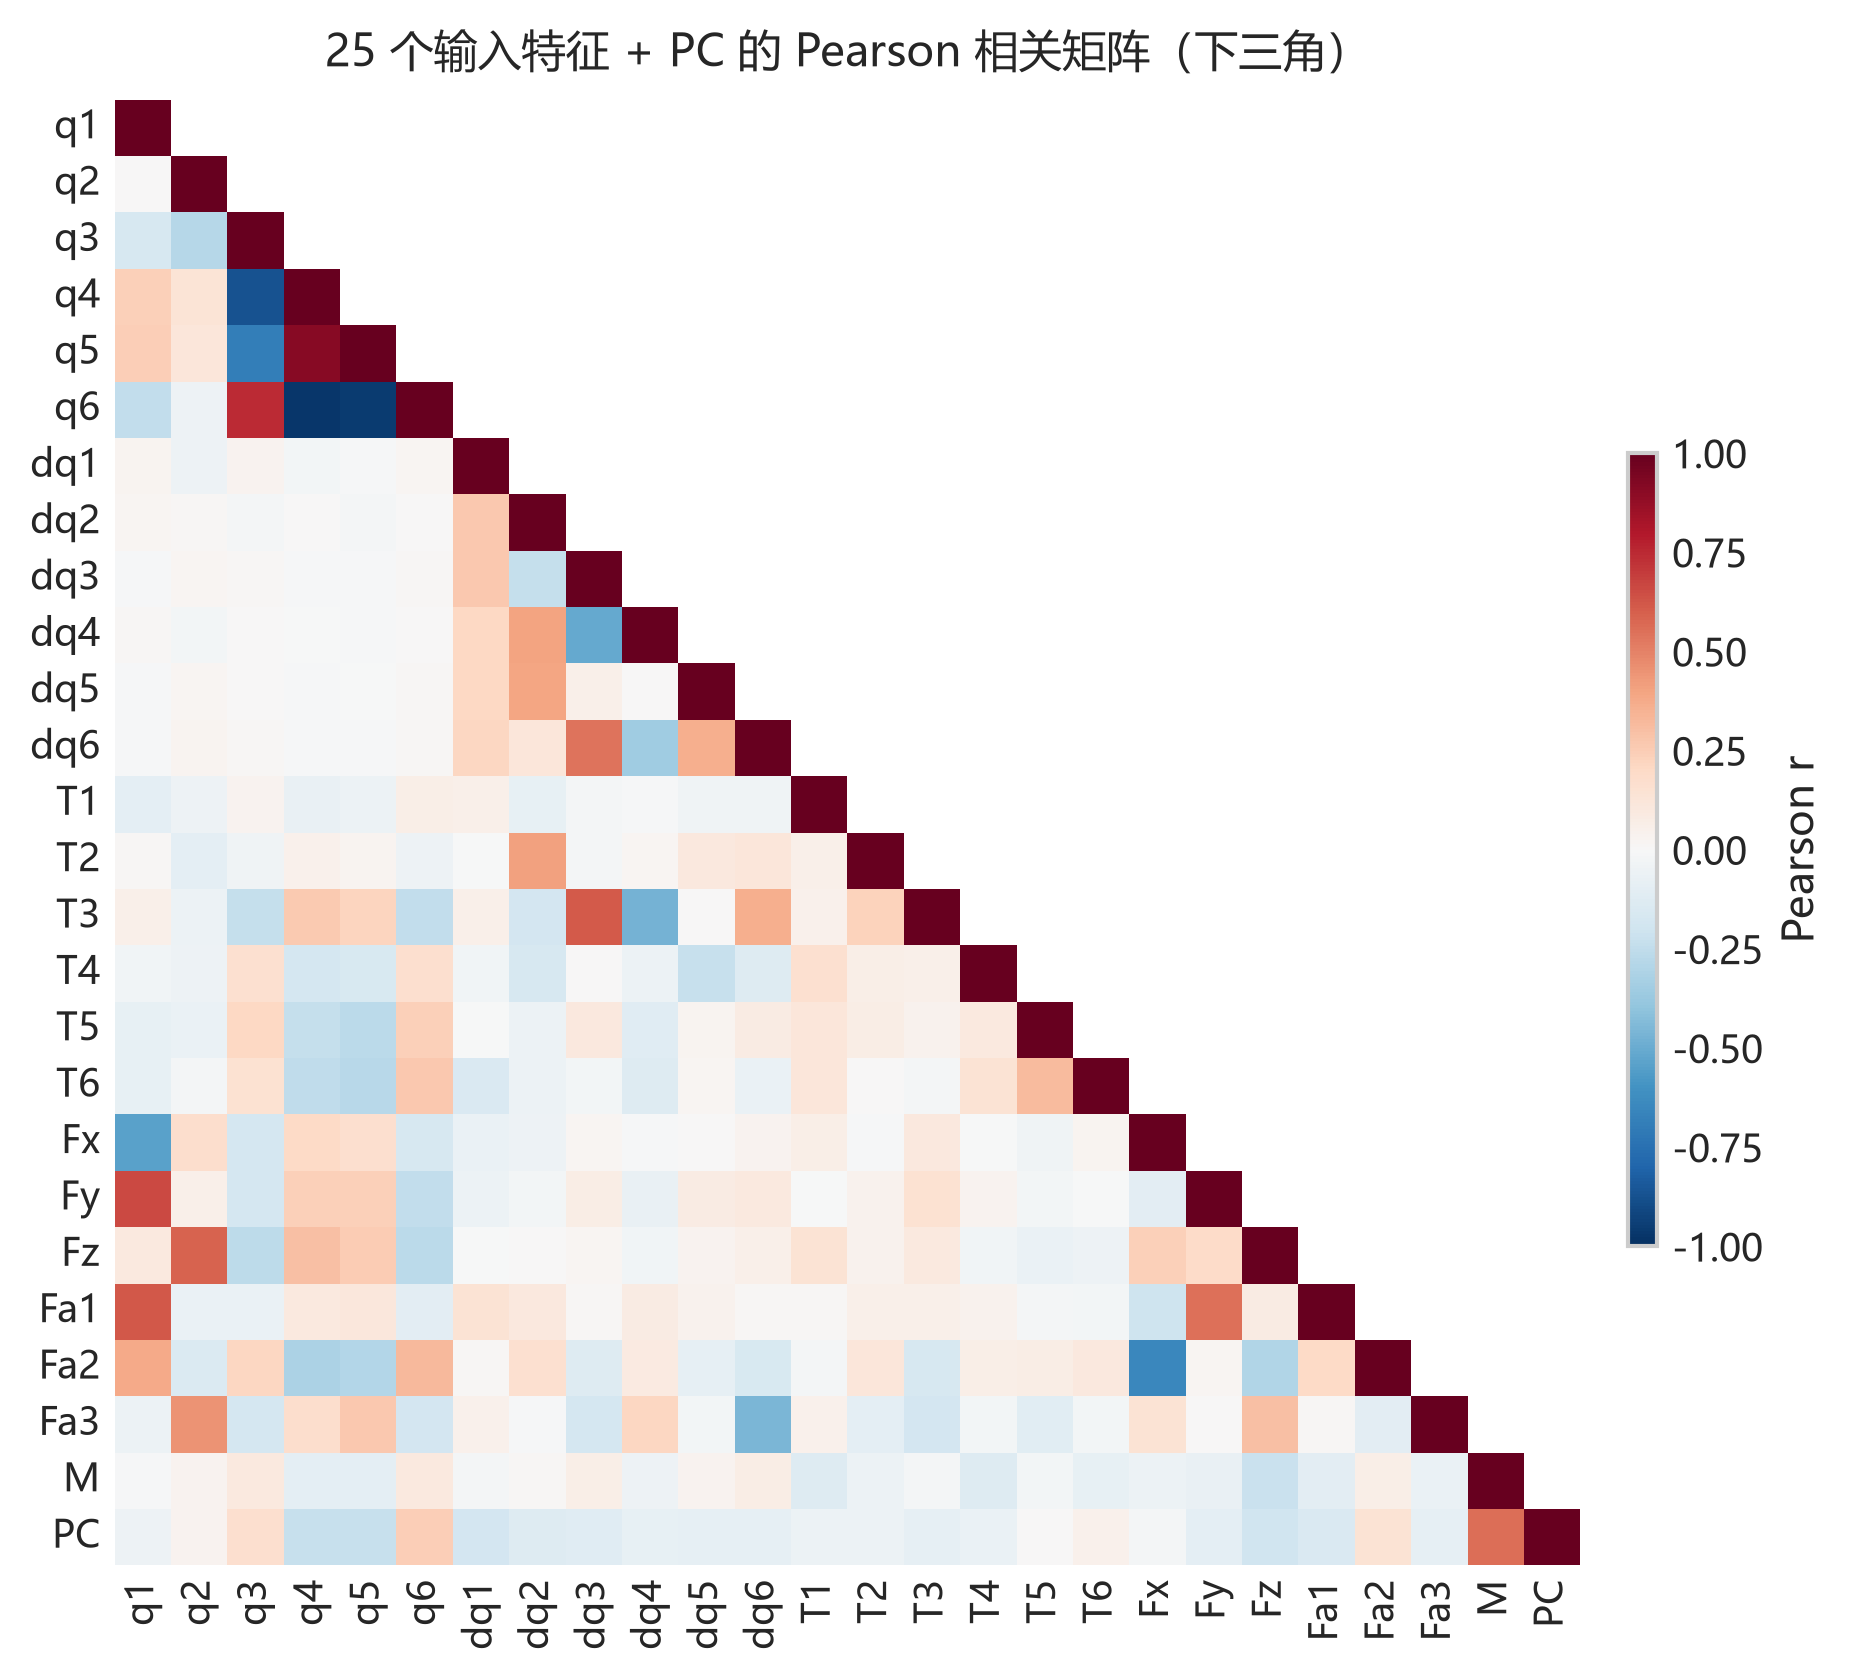

[saved] figures\feature_analysis\03b_pearson_bar.png  (300 dpi)


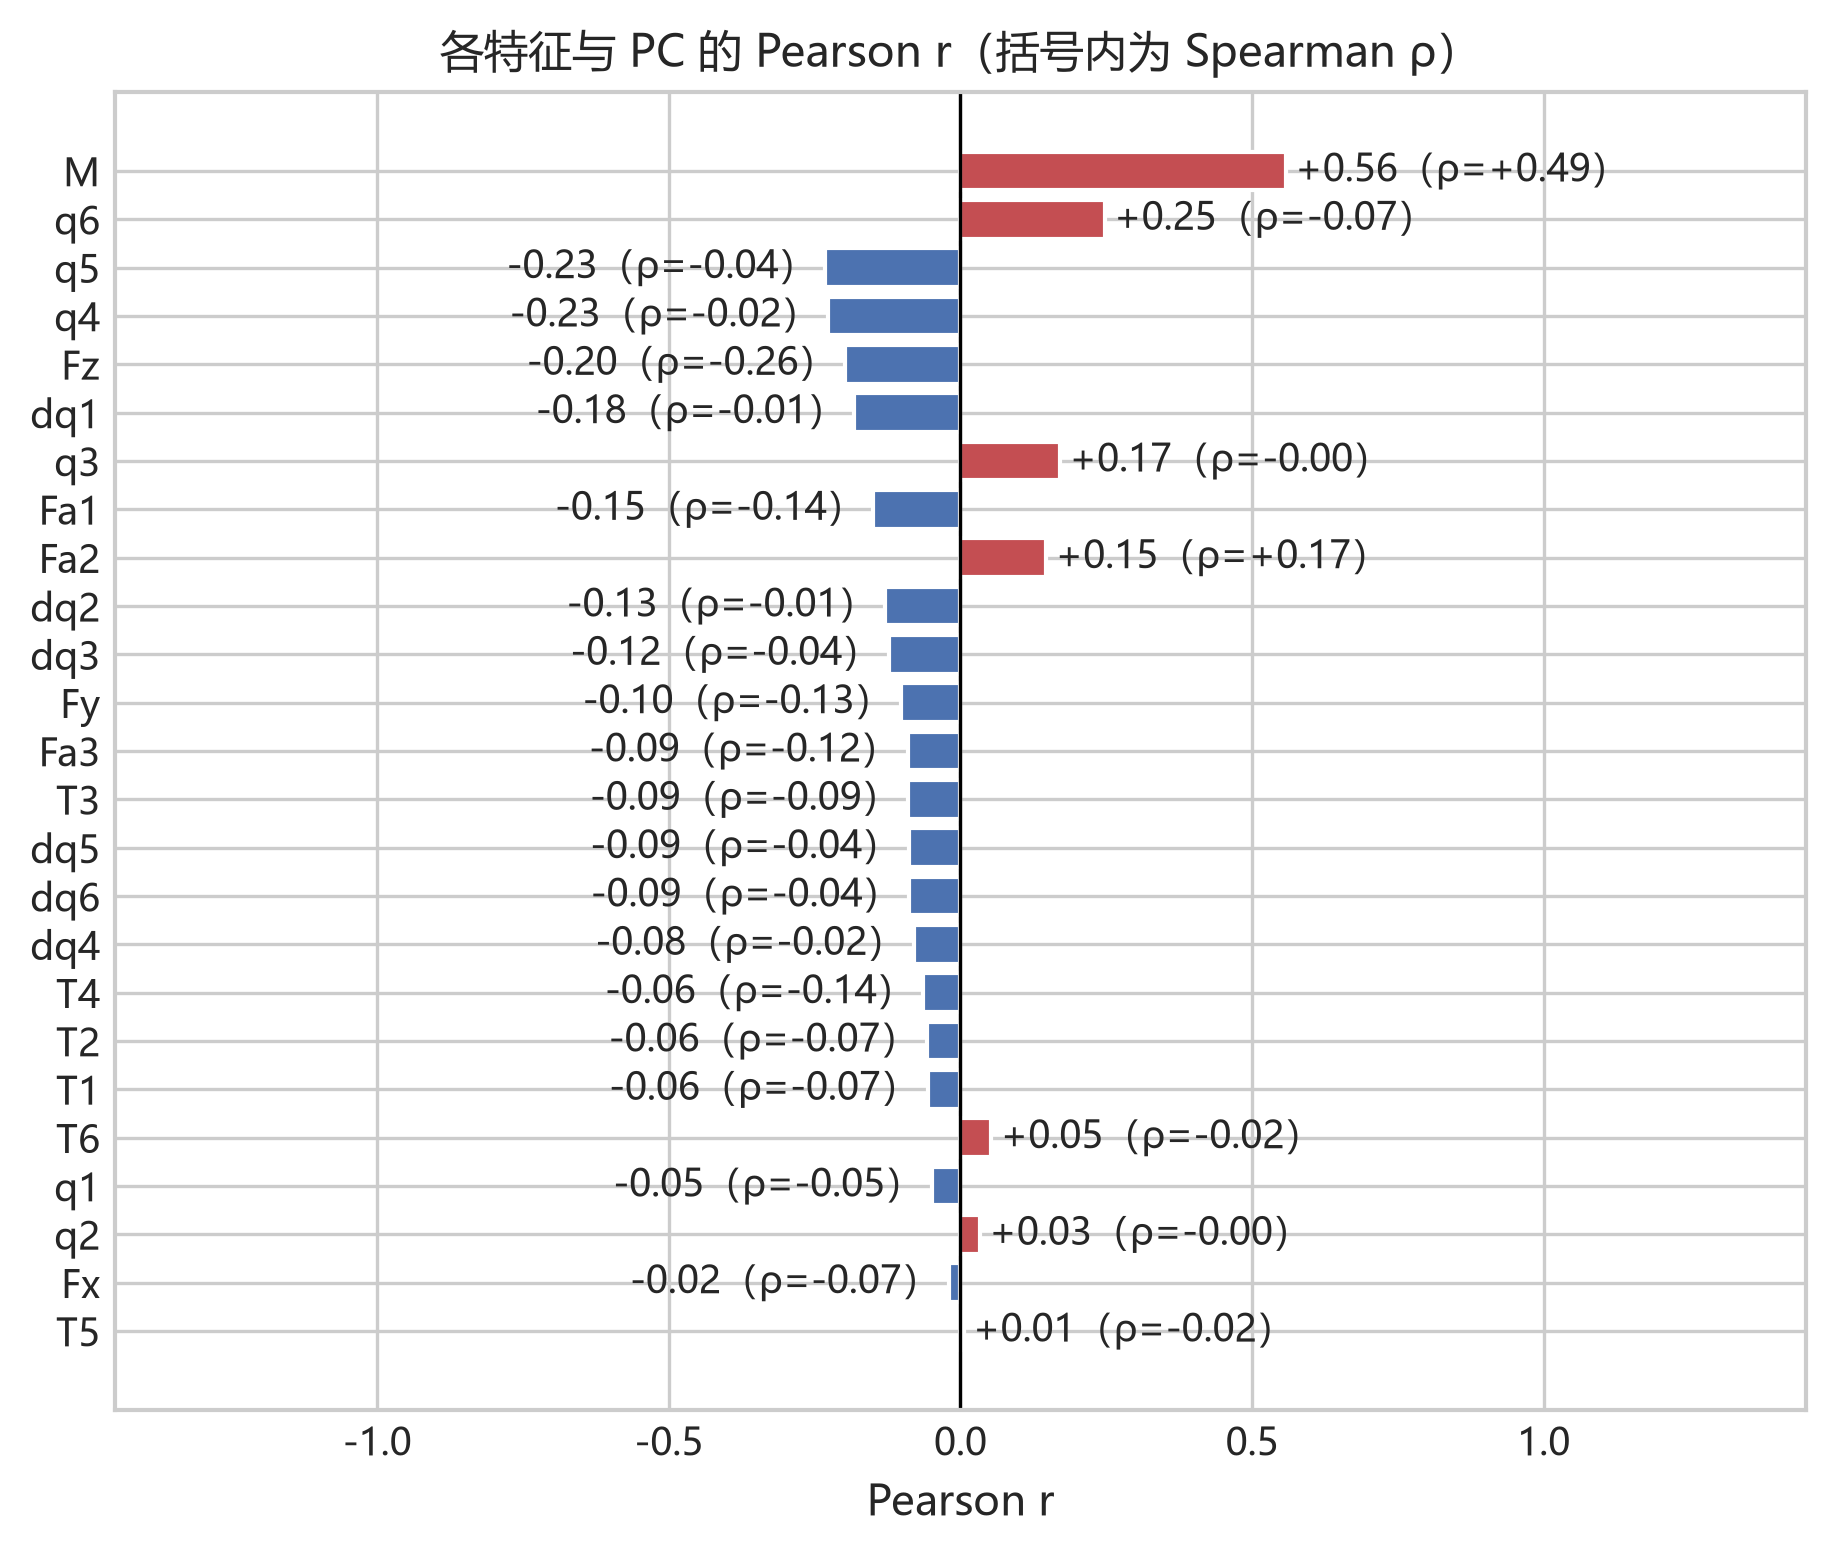

In [6]:
# ============================================================
# 2.1 线性相关：Pearson / Spearman
# ============================================================
corr_input = df[FEATS + [TARGET]]
pear = corr_input.corr(method="pearson")
spear = corr_input.corr(method="spearman")

lin = pd.DataFrame({
    "Pearson r": pear[TARGET].drop(TARGET),
    "Spearman rho": spear[TARGET].drop(TARGET),
})
lin["|r|"] = lin["Pearson r"].abs()
lin["r^2"] = lin["Pearson r"] ** 2
lin = lin.sort_values("|r|", ascending=False)

print("各输入特征与 PC 的线性相关（按 |r| 降序）:")
display(lin.round(4))
print(f"|r| > 0.5 的特征数: {(lin['|r|'] > 0.5).sum()} / {len(FEATS)}")
print(f"|r| < 0.1 的特征数: {(lin['|r|'] < 0.1).sum()} / {len(FEATS)}")

# ---------- 03a Pearson 相关矩阵（方格等边、无网格线、纵轴完整）----------
mask = np.triu(np.ones_like(pear, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(FIG_W, 14.6 / 2.54))
# 左侧留行标签、右侧另设色条轴，使 26×26 方阵以 ~12.4 cm 见方铺满版心
fig.subplots_adjust(left=0.075, right=0.865, top=0.945, bottom=0.095)
sns.heatmap(
    pear, ax=ax, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True,                 # 每个格子为正方形
    linewidths=0,                # 不画格线
    xticklabels=pear.columns, yticklabels=pear.index,
    cbar=False,                  # 色条单独放置，避免挤压方阵
)
ax.grid(False)                   # 去掉 seaborn 背景网格（灰色线）
ax.tick_params(labelsize=FS_TICK, length=0)
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=FS_TICK)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=FS_TICK)
ax.set_title("25 个输入特征 + PC 的 Pearson 相关矩阵（下三角）", fontsize=FS_TITLE, pad=8)

cax = fig.add_axes([0.888, 0.28, 0.016, 0.46])
_cb = fig.colorbar(ax.collections[0], cax=cax)
_cb.ax.tick_params(labelsize=FS_TICK)
_cb.set_label("Pearson r", fontsize=FS_LABEL)
savefig(fig, "03a_pearson_matrix")
plt.show()

# ---------- 03b 各特征与 PC 的 Pearson r ----------
order = lin.index[::-1]
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in lin.loc[order, "Pearson r"]]
fig, ax = plt.subplots(figsize=fig_size(0.85))
ax.barh(order, lin.loc[order, "Pearson r"], color=colors)
ax.axvline(0, color="k", lw=0.8)
for i, (v, rho) in enumerate(zip(lin.loc[order, "Pearson r"], lin.loc[order, "Spearman rho"])):
    ax.text(v + (0.015 if v >= 0 else -0.015), i, f"{v:+.2f}（ρ={rho:+.2f}）",
            va="center", ha="left" if v >= 0 else "right", fontsize=FS_TICK)
ax.set_xlim(-1.45, 1.45)
ax.set_title("各特征与 PC 的 Pearson r（括号内为 Spearman ρ）", fontsize=FS_TITLE)
ax.set_xlabel("Pearson r", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "03b_pearson_bar")
plt.show()

特征间 |r| > 0.9 的对数: 3


,特征A,特征B,Pearson r
1,q4,q6,-0.972
2,q5,q6,-0.957
0,q4,q5,0.913



方差膨胀因子 VIF（>10 视为严重共线）:


,VIF
q4,137.96
q6,120.62
q5,19.33
q3,16.12
q1,4.89
q2,3.18
dq3,2.86
Fx,2.85
dq6,2.82
Fy,2.50



训练: 93 条轨迹 / 83400 样本 | 验证: 23 条轨迹 / 22000 样本
均值基准                               R²=0.0000  RMSE=10.724 W
线性回归（当前时刻 25 维）                    R²=0.3982  RMSE= 8.319 W

标准化回归系数（特征变化 1 个标准差对应的 PC 变化，单位 W）:


,coef
q6,6.458
M,4.544
q4,4.111
dq3,-1.996
q5,1.665
dq2,-1.549
Fx,1.536
Fa2,1.312
q3,1.165
Fa3,-1.038


[saved] figures\feature_analysis\04a_resid_vs_pred.png  (300 dpi)


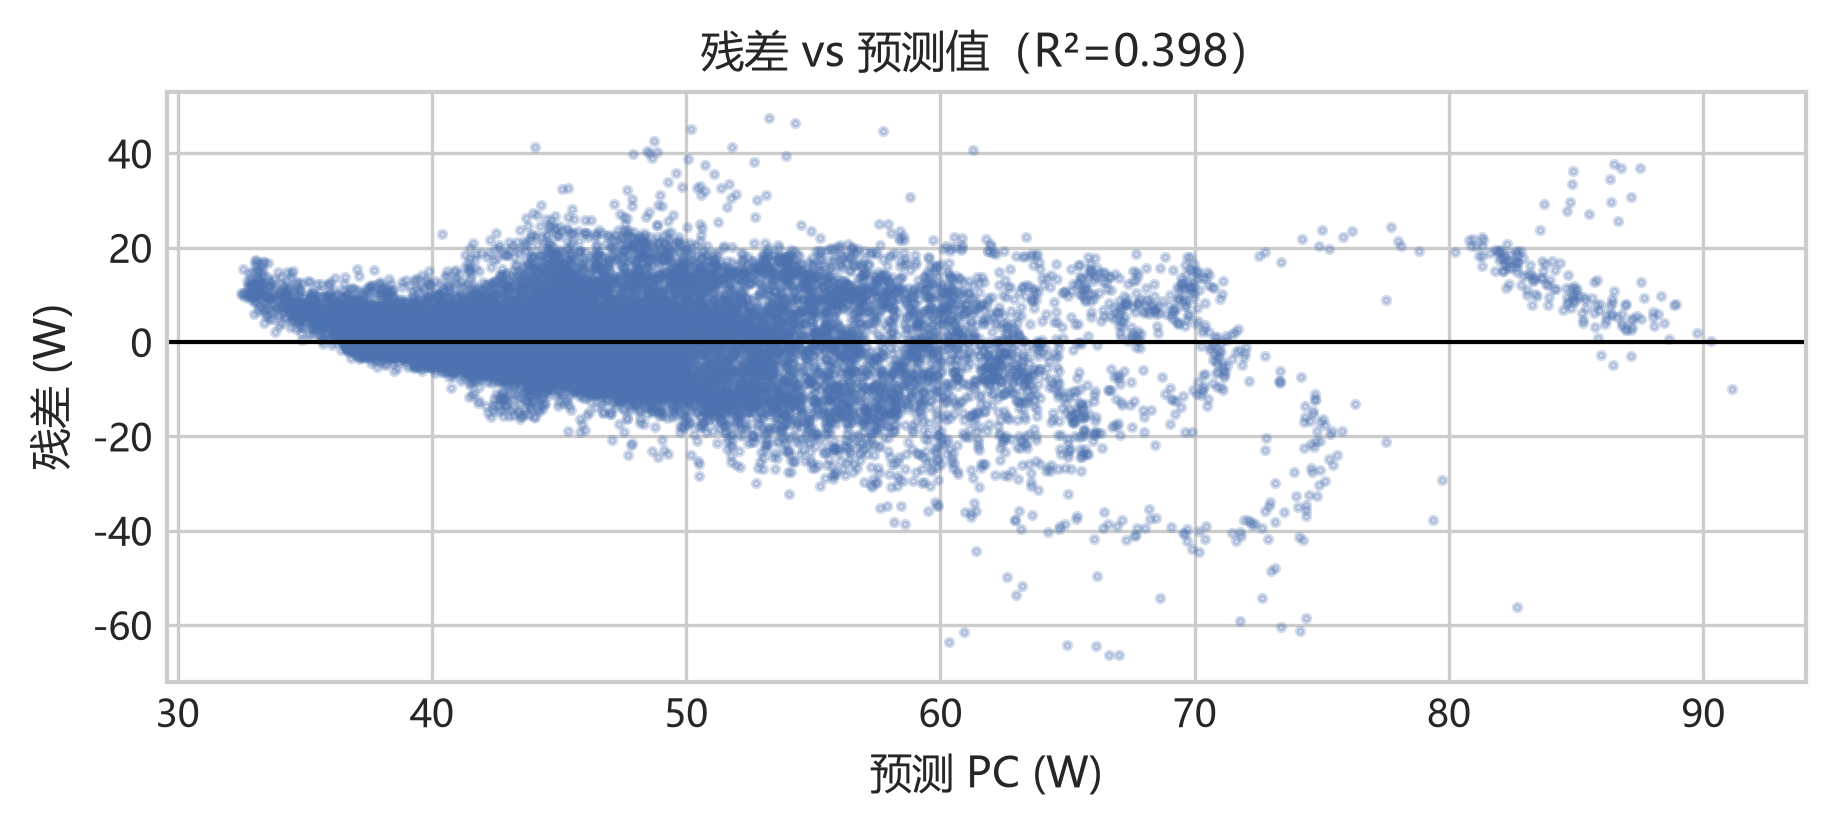

[saved] figures\feature_analysis\04b_pred_vs_true.png  (300 dpi)


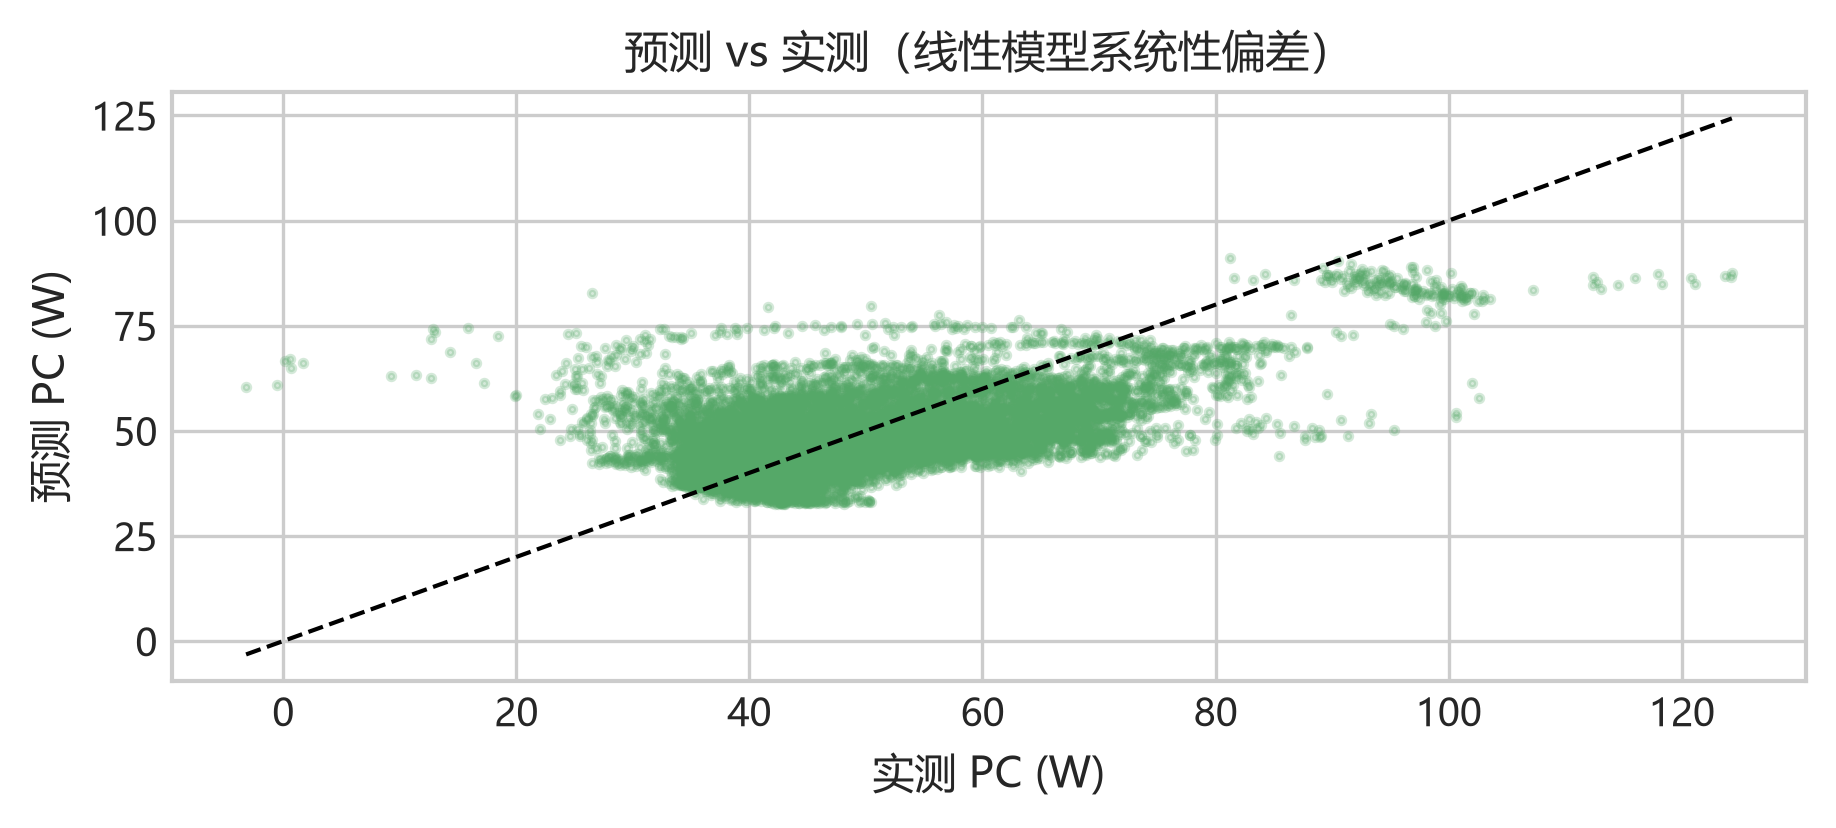


残差标准差 8.315 W，>20 W 的残差占比 3.00%


In [7]:
# ============================================================
# 2.2 多重共线性诊断 + 线性回归基线
# ============================================================
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error

# --- 特征之间的强线性相关对 ---
pairs = []
for i, a in enumerate(FEATS):
    for b in FEATS[i + 1:]:
        r = pear.loc[a, b]
        if abs(r) > 0.9:
            pairs.append((a, b, round(r, 3)))
pairs_df = pd.DataFrame(pairs, columns=["特征A", "特征B", "Pearson r"])
pairs_df = pairs_df.reindex(pairs_df["Pearson r"].abs().sort_values(ascending=False).index)
print(f"特征间 |r| > 0.9 的对数: {len(pairs_df)}")
display(pairs_df.head(15))

# --- VIF ---
X_all = df[FEATS].to_numpy(float)
vif = pd.Series(
    [variance_inflation_factor(X_all, i) for i in range(len(FEATS))], index=FEATS
).sort_values(ascending=False)
print("\n方差膨胀因子 VIF（>10 视为严重共线）:")
display(vif.round(2).to_frame("VIF"))

# --- 固定按轨迹划分（后续所有模型对比共用）---
rng = np.random.default_rng(42)
traj_ids = np.sort(df.trajectory_id.unique())
rng.shuffle(traj_ids)
n_val = int(round(0.2 * len(traj_ids)))
VAL_IDS = np.sort(traj_ids[:n_val])
TR_IDS = np.sort(traj_ids[n_val:])
tr_m = df.trajectory_id.isin(TR_IDS).to_numpy()
te_m = ~tr_m
X = df[FEATS].to_numpy(float)
y = df[TARGET].to_numpy(float)
print(f"\n训练: {len(TR_IDS)} 条轨迹 / {tr_m.sum()} 样本 | 验证: {len(VAL_IDS)} 条轨迹 / {te_m.sum()} 样本")


def report(name, pred, yte):
    r2 = r2_score(yte, pred)
    rmse = mean_squared_error(yte, pred) ** 0.5
    print(f"{name:<34s} R²={r2:.4f}  RMSE={rmse:6.3f} W")
    return {"model": name, "R2": r2, "RMSE": rmse}


results = []
print(f"{'均值基准':<34s} R²={0.0:.4f}  RMSE={y[te_m].std():6.3f} W")

lin_model = make_pipeline(StandardScaler(), LinearRegression()).fit(X[tr_m], y[tr_m])
pred_lin = lin_model.predict(X[te_m])
results.append(report("线性回归（当前时刻 25 维）", pred_lin, y[te_m]))

coef = pd.Series(lin_model[-1].coef_, index=FEATS).sort_values(key=np.abs, ascending=False)
print("\n标准化回归系数（特征变化 1 个标准差对应的 PC 变化，单位 W）:")
display(coef.round(3).to_frame("coef"))

# ---------- 04a 残差 vs 预测值 ----------
resid = y[te_m] - pred_lin
fig, ax = plt.subplots(figsize=fig_size(0.46))
ax.scatter(pred_lin, resid, s=3, alpha=0.25, color="#4C72B0")
ax.axhline(0, color="k", lw=1)
ax.set_title(f"残差 vs 预测值（R²={r2_score(y[te_m], pred_lin):.3f}）", fontsize=FS_TITLE)
ax.set_xlabel("预测 PC (W)", fontsize=FS_LABEL)
ax.set_ylabel("残差 (W)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "04a_resid_vs_pred")
plt.show()

# ---------- 04b 预测 vs 实测 ----------
fig, ax = plt.subplots(figsize=fig_size(0.46))
ax.scatter(y[te_m], pred_lin, s=3, alpha=0.25, color="#55A868")
lim = [np.min(y[te_m]), np.max(y[te_m])]
ax.plot(lim, lim, "k--", lw=1)
ax.set_title("预测 vs 实测（线性模型系统性偏差）", fontsize=FS_TITLE)
ax.set_xlabel("实测 PC (W)", fontsize=FS_LABEL)
ax.set_ylabel("预测 PC (W)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "04b_pred_vs_true")
plt.show()

print(f"\n残差标准差 {resid.std():.3f} W，>20 W 的残差占比 {(np.abs(resid) > 20).mean() * 100:.2f}%")

## 3. 非线性关系探究

机器人功率与关节速度的关系并不线性：无论是电机铜损（∝ 力矩²）、粘性摩擦（∝ 速度）还是重力项（∝ cos q），都隐含**绝对值和平方项**。因此需要四种互补的手段：

| 方法 | 能回答的问题 |
|---|---|
| 分箱均值曲线 + hexbin | 关系形状长什么样（U 型？饱和？阈值？） |
| 互信息 MI / 距离相关 dCor | 有无**任意形式**的依赖（不限于函数关系） |
| 单特征 GBDT R² | 单个特征最多能解释多少方差（相对线性 R² 的增益） |
| 全特征 GBDT + PDP / 2D-PDP | 多特征组合后谁重要、边际效应与交互长什么样 |

[saved] figures\feature_analysis\05_nonlinear_shape.png  (300 dpi)


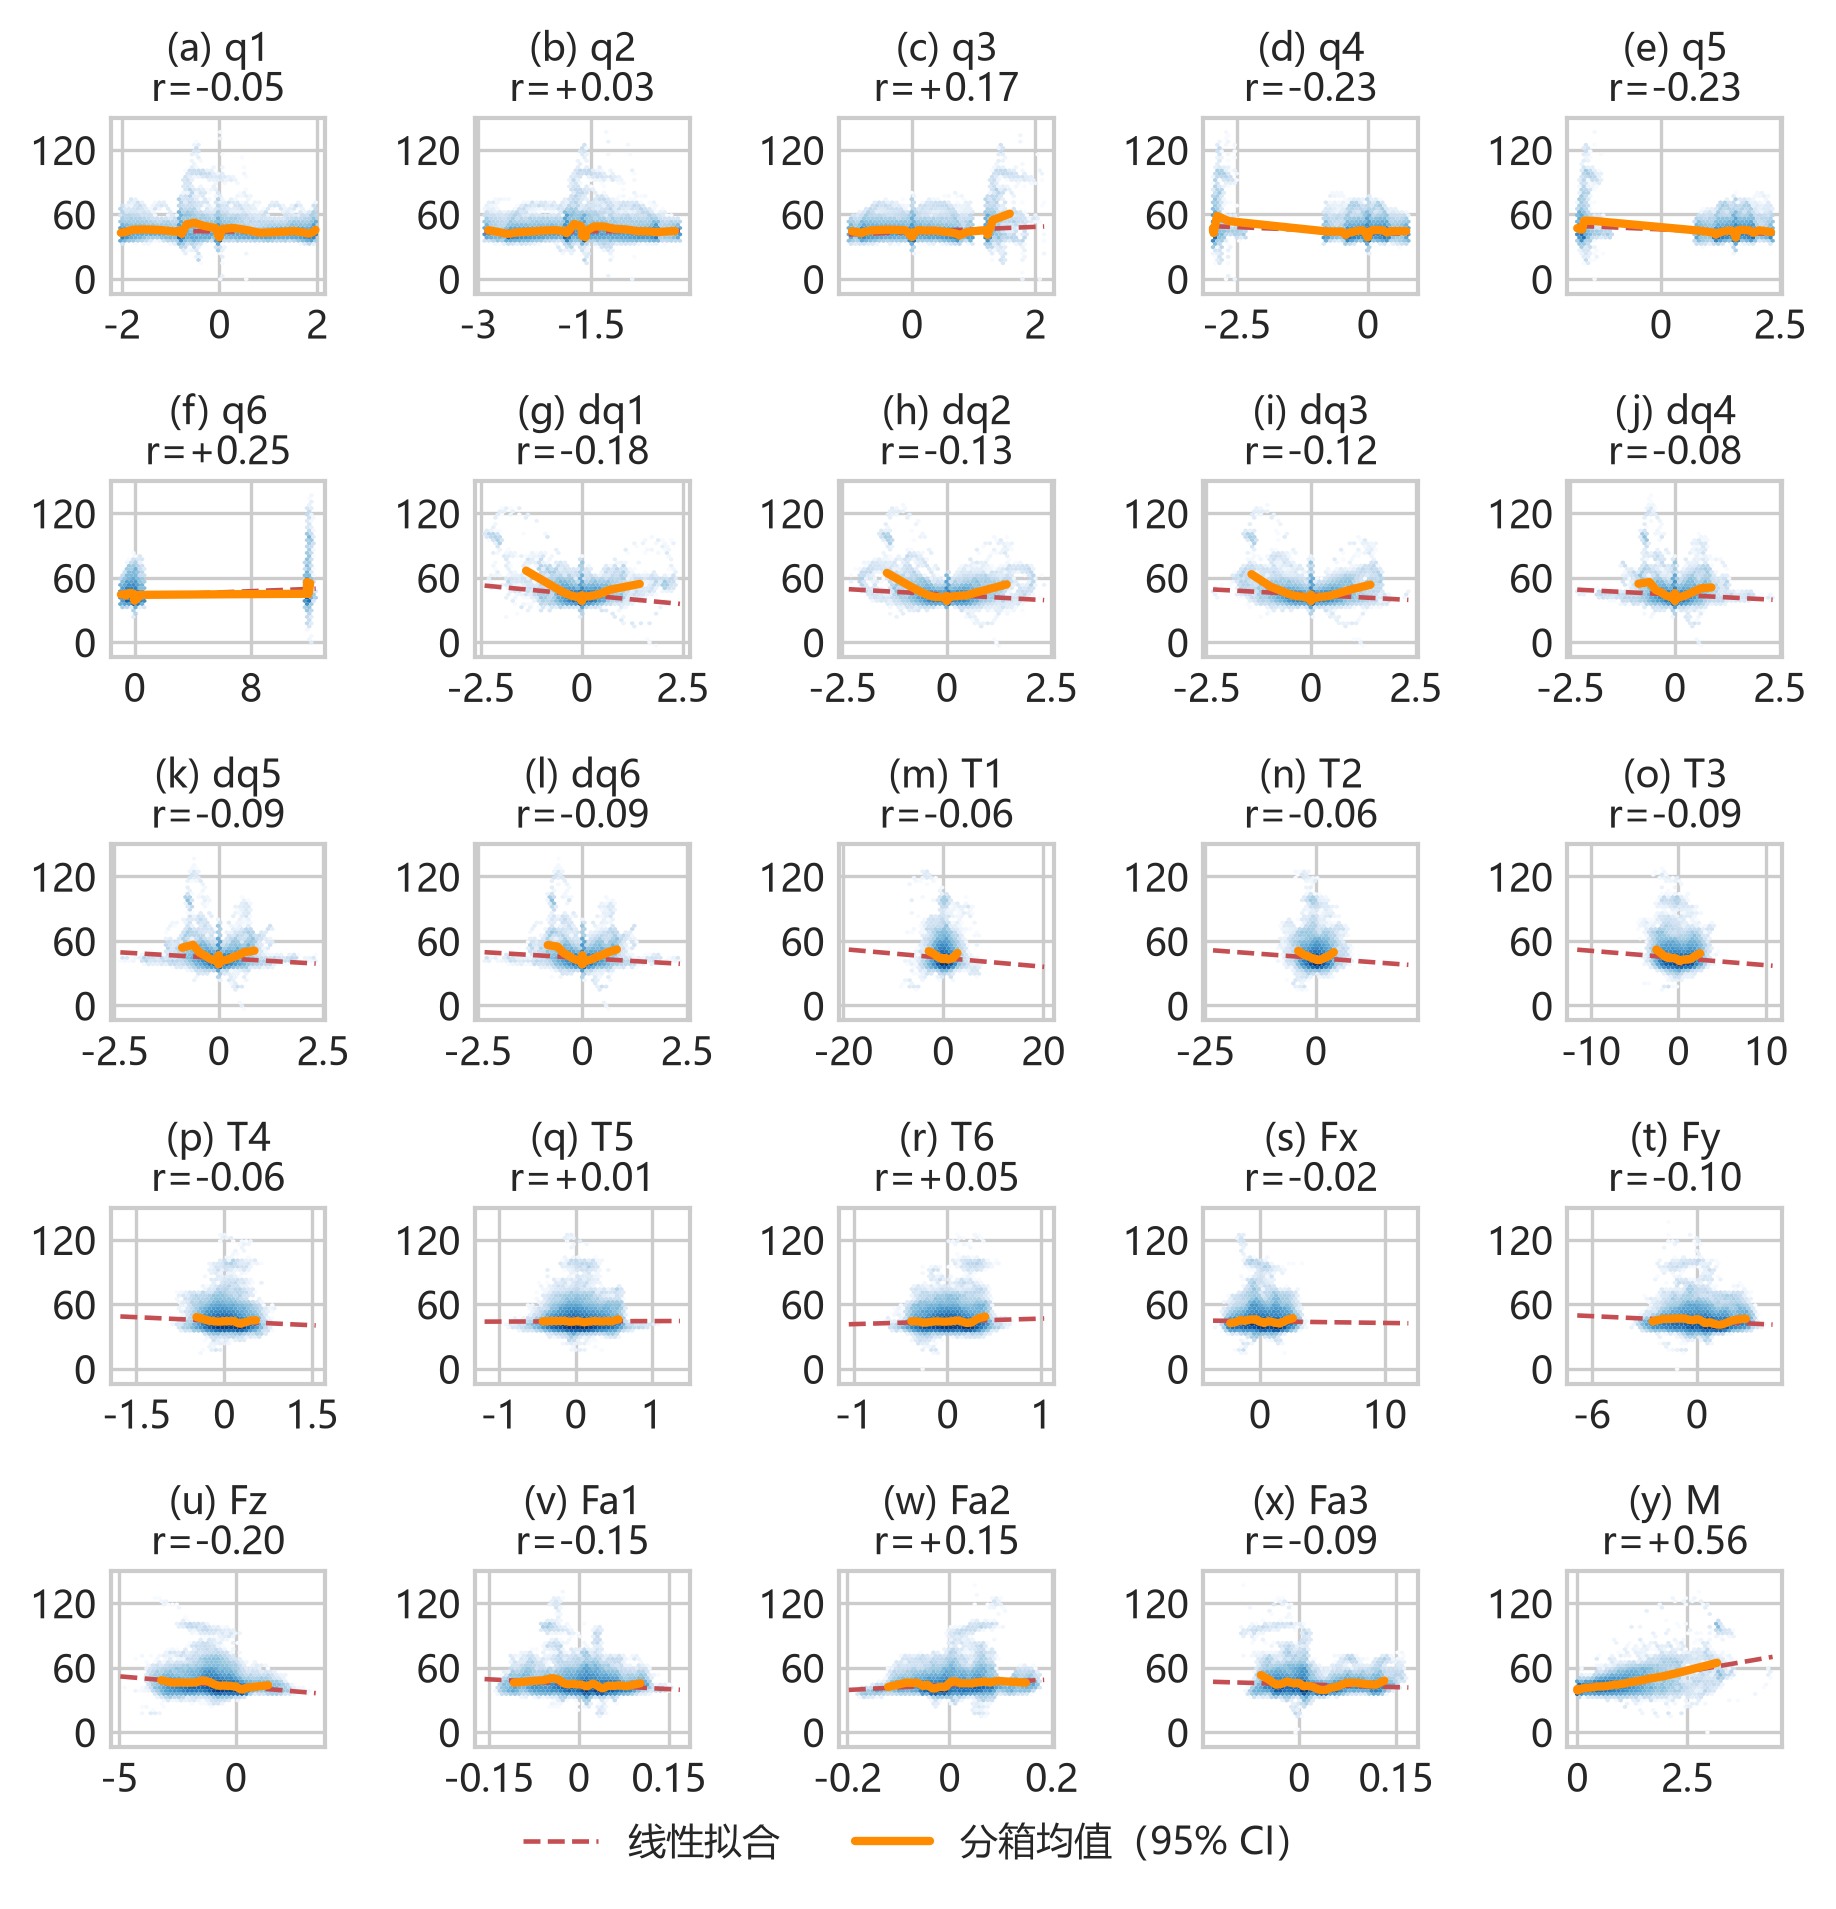

In [8]:
# ============================================================
# 3.1 非线性形态：hexbin 密度 + 线性拟合 vs 分箱均值
# ============================================================
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, StrMethodFormatter


def binned_curve(x, y, n_bins=30):
    """按分位数分箱，返回 (箱内中位 x, 箱内 y 均值, 标准误)"""
    b = pd.qcut(pd.Series(x).rank(method="first"), n_bins, labels=False).to_numpy()
    g = pd.DataFrame({"b": b, "x": np.asarray(x), "y": np.asarray(y)}).groupby("b")
    xc = g["x"].median().to_numpy()
    ym = g["y"].mean().to_numpy()
    se = g["y"].std().to_numpy() / np.sqrt(g["y"].size().to_numpy())
    return xc, ym, se


fig, axes = plt.subplots(5, 5, figsize=fig_size(1.02))
for ax, c, j, tag in zip(axes.ravel(), FEATS, range(len(FEATS)), ALPHA25):
    xj = X[:, j]
    hb = ax.hexbin(xj, y, gridsize=45, cmap="Blues", mincnt=5, bins="log", linewidths=0)
    xc, ym, se = binned_curve(xj, y)
    slope, icpt = np.polyfit(xj, y, 1)
    ax.plot(np.sort(xj), slope * np.sort(xj) + icpt, color="#C44E52", ls="--", lw=1.1)
    ax.fill_between(xc, ym - 1.96 * se, ym + 1.96 * se, color="orange", alpha=0.25)
    ax.plot(xc, ym, color="darkorange", lw=2.0)
    tag_title(ax, tag, f"{c}\nr={np.corrcoef(xj, y)[0, 1]:+.2f}", fontsize=FS_TICK)
    ax.tick_params(labelsize=FS_TICK)
    ax.xaxis.set_major_locator(MaxNLocator(2))
    ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.set_ylabel("")
    ax.set_xlabel("")

_h = [Line2D([], [], color="#C44E52", ls="--", lw=1.1, label="线性拟合"),
      Line2D([], [], color="darkorange", lw=2.0, label="分箱均值（95% CI）")]
fig.legend(handles=_h, loc="lower center", ncol=2, fontsize=FS_LEGEND, frameon=False,
           bbox_to_anchor=(0.5, -0.005))
fig.tight_layout(rect=(0, 0.022, 1, 1))
savefig(fig, "05_nonlinear_shape")
plt.show()

In [9]:
# ============================================================
# 3.2 非线性强度量化：线性 R² vs 二次多项式 / GBDT / 互信息 / 距离相关
# ============================================================
import lightgbm as lgb
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import PolynomialFeatures


def distance_corr(a, b):
    """距离相关系数 dCor ∈ [0, 1]，=0 当且仅当独立"""
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    a = (a - a.mean()) / a.std()
    b = (b - b.mean()) / b.std()
    A = np.abs(a[:, None] - a[None, :])
    B = np.abs(b[:, None] - b[None, :])
    A = A - A.mean(0, keepdims=True) - A.mean(1, keepdims=True) + A.mean()
    B = B - B.mean(0, keepdims=True) - B.mean(1, keepdims=True) + B.mean()
    dcov2 = (A * B).mean()
    dx = (A * A).mean()
    dy = (B * B).mean()
    return float(np.sqrt(max(dcov2, 0.0) / np.sqrt(dx * dy)))


# 互信息：随机抽样 3 万行，kNN 估计
rng_mi = np.random.default_rng(0)
mi_rows = rng_mi.choice(len(df), size=30000, replace=False)
mi_vals = mutual_info_regression(X[mi_rows], y[mi_rows], n_neighbors=5, random_state=0)

# 距离相关：抽样 2000 行（O(n²) 复杂度）
dc_rows = rng_mi.choice(len(df), size=2000, replace=False)
dcor_vals = np.array([distance_corr(X[dc_rows, j], y[dc_rows]) for j in range(len(FEATS))])

# 单特征模型：线性 / 二次多项式 / GBDT（同一按轨迹划分）
r2_lin1, r2_poly2, r2_gbdt1 = [], [], []
for j in range(len(FEATS)):
    x1 = X[:, [j]]
    m_lin = LinearRegression().fit(x1[tr_m], y[tr_m])
    r2_lin1.append(r2_score(y[te_m], m_lin.predict(x1[te_m])))
    m_poly = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()).fit(x1[tr_m], y[tr_m])
    r2_poly2.append(r2_score(y[te_m], m_poly.predict(x1[te_m])))
    g1 = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.08, num_leaves=31,
                           min_child_samples=60, subsample=0.9, subsample_freq=1,
                           random_state=0, verbose=-1, n_jobs=-1)
    g1.fit(x1[tr_m], y[tr_m])
    r2_gbdt1.append(r2_score(y[te_m], g1.predict(x1[te_m])))

nl = pd.DataFrame({
    "Pearson r": pear.loc[FEATS, TARGET],
    "线性R²(单特征)": r2_lin1,
    "二次多项式R²": r2_poly2,
    "GBDT R²(单特征)": r2_gbdt1,
    "互信息MI": mi_vals,
    "距离相关dCor": dcor_vals,
}, index=FEATS)
nl["非线性增益ΔR²"] = nl["GBDT R²(单特征)"] - nl["线性R²(单特征)"]
nl["非线性增益ΔR²_lag"] = nl["GBDT R²(单特征)"] - nl["二次多项式R²"]
nl = nl.sort_values("GBDT R²(单特征)", ascending=False)
print("单特征解释能力对比（同一按轨迹 8:2 划分的验证集）:")
display(nl.round(4))

print(f"\n线性R²合计(非可加): 各特征线性 R² 最大值 = {nl['线性R²(单特征)'].max():.4f}")
print(f"GBDT R² 最大值 = {nl['GBDT R²(单特征)'].max():.4f}")
print(f"平均非线性增益 ΔR² = {nl['非线性增益ΔR²'].mean():.4f}")
print("互信息与 |Pearson r| 的秩相关: "
      f"{stats.spearmanr(nl['互信息MI'], nl['Pearson r'].abs()).statistic:.3f}")

单特征解释能力对比（同一按轨迹 8:2 划分的验证集）:


,Pearson r,线性R²(单特征),二次多项式R²,GBDT R²(单特征),互信息MI,距离相关dCor,非线性增益ΔR²,非线性增益ΔR²_lag
dq1,-0.1818,-0.0496,0.2265,0.2772,0.2472,0.3876,0.3267,0.0506
dq4,-0.0797,-0.0581,-0.0049,0.2521,0.2164,0.3170,0.3101,0.2570
dq3,-0.1227,-0.0585,0.2217,0.2431,0.2348,0.3158,0.3017,0.0214
dq5,-0.0885,-0.0559,-0.0043,0.2342,0.2124,0.3062,0.2901,0.2385
dq6,-0.0878,-0.0564,0.0044,0.2217,0.2060,0.2979,0.2781,0.2173
M,0.5582,0.3075,0.1957,0.1870,0.3173,0.5909,-0.1204,-0.0087
q3,0.1712,-0.0295,0.0069,0.1174,0.2289,0.2165,0.1470,0.1106
q5,-0.2318,-0.0151,-0.0203,0.0966,0.2062,0.2513,0.1118,0.1170
Fa3,-0.0906,-0.0612,0.0210,0.0944,0.1388,0.1864,0.1556,0.0734
q4,-0.2266,-0.0168,-0.0219,0.0899,0.2069,0.2499,0.1068,0.1118



线性R²合计(非可加): 各特征线性 R² 最大值 = 0.3075
GBDT R² 最大值 = 0.2772
平均非线性增益 ΔR² = 0.0941
互信息与 |Pearson r| 的秩相关: 0.634


[saved] figures\feature_analysis\06a_r_vs_dcor.png  (300 dpi)


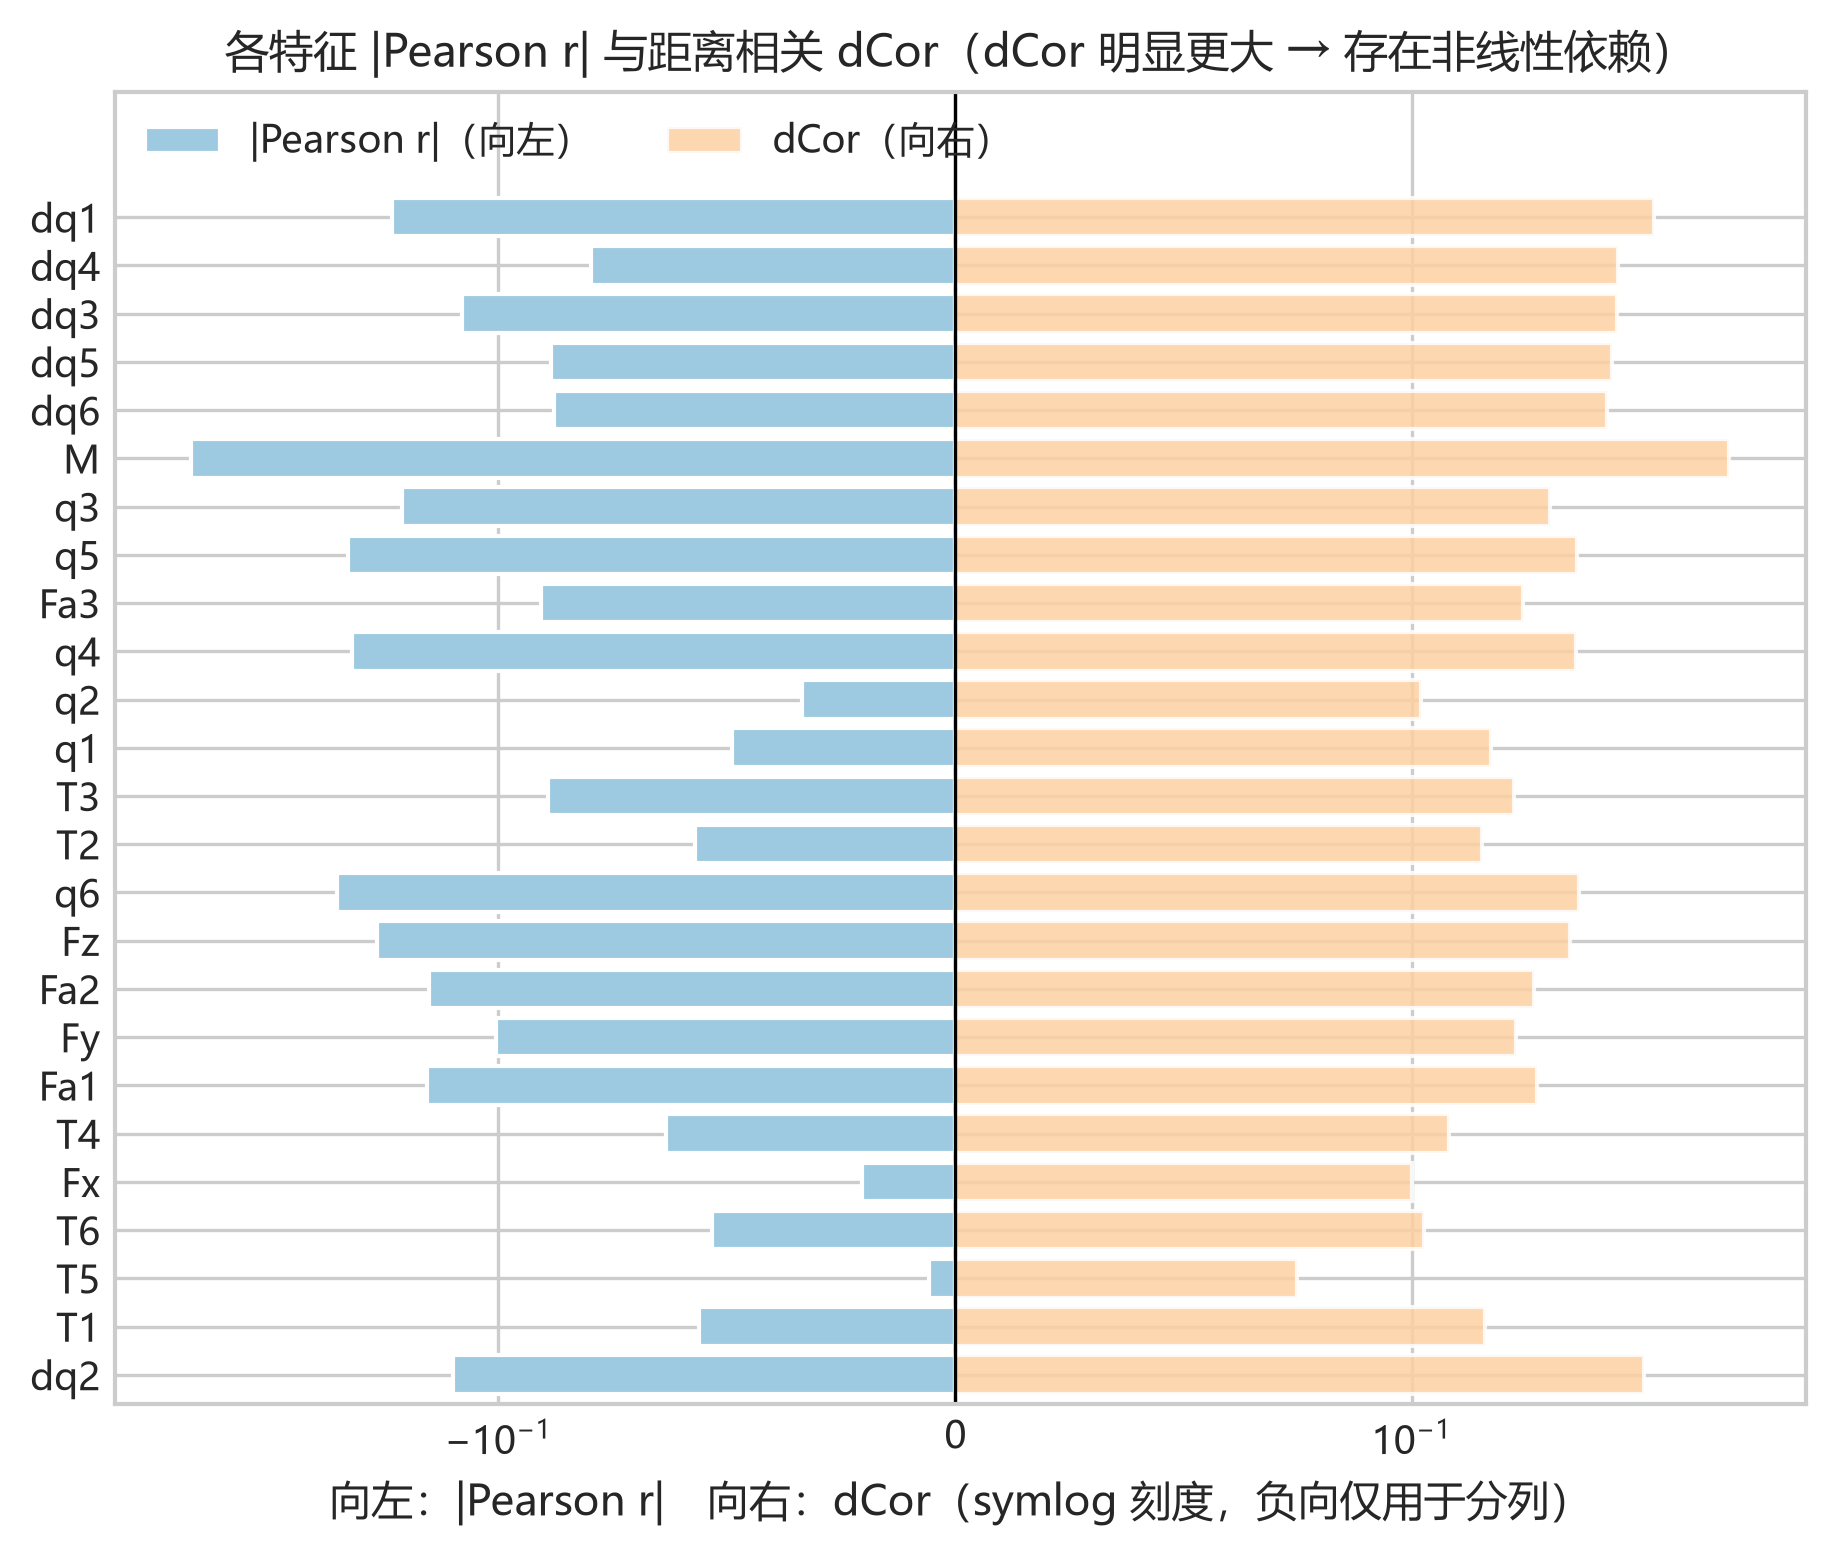

[saved] figures\feature_analysis\06b_linear_vs_gbdt_r2.png  (300 dpi)


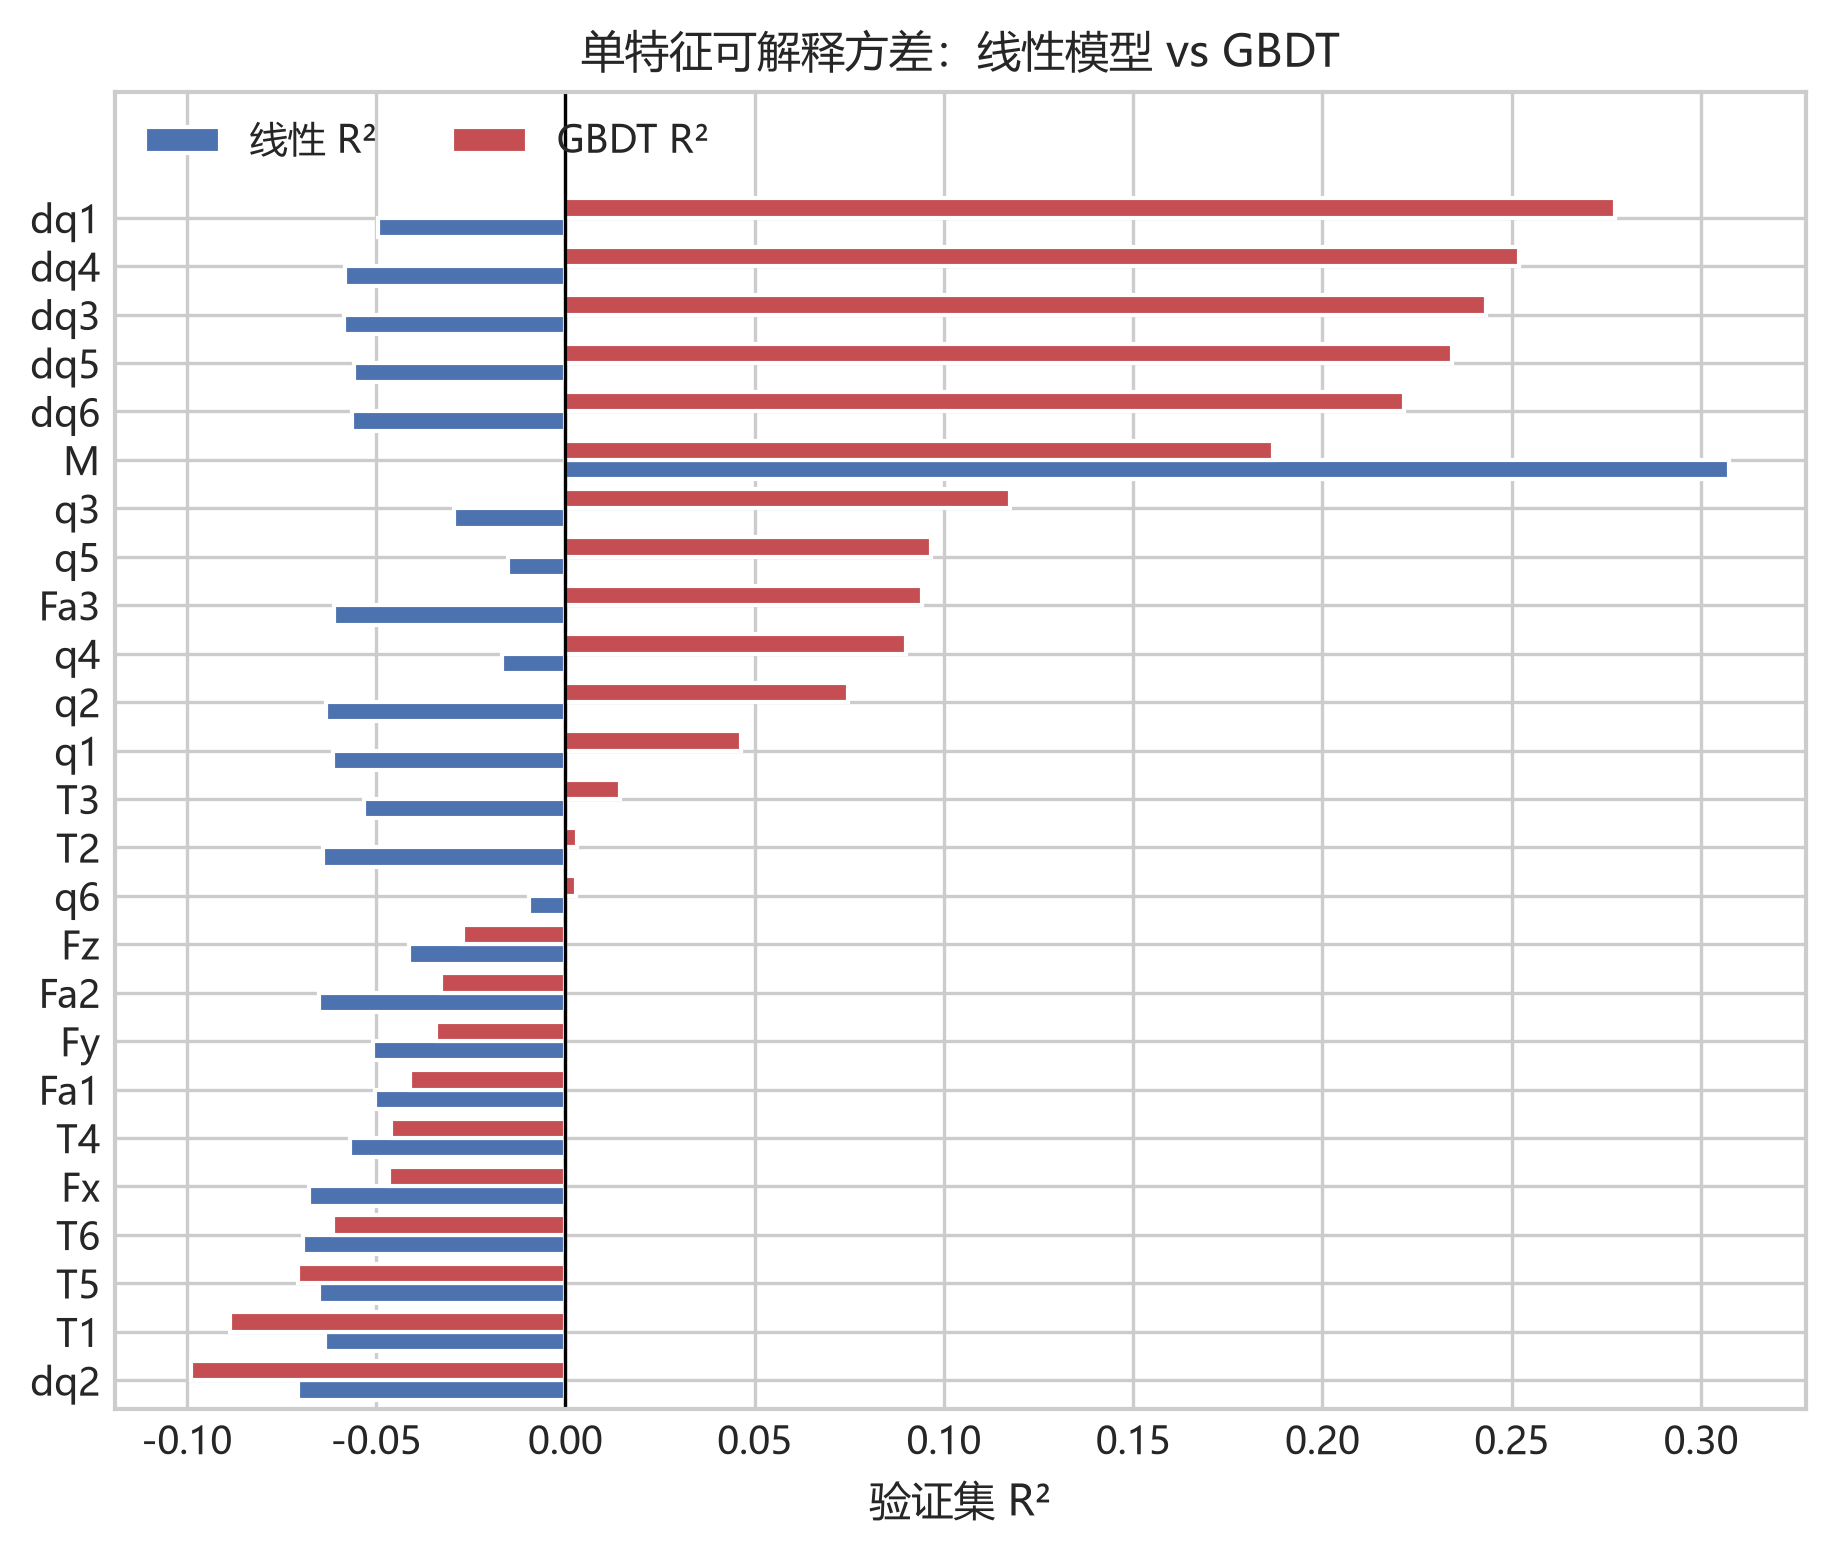

[saved] figures\feature_analysis\06c_r_vs_mi.png  (300 dpi)


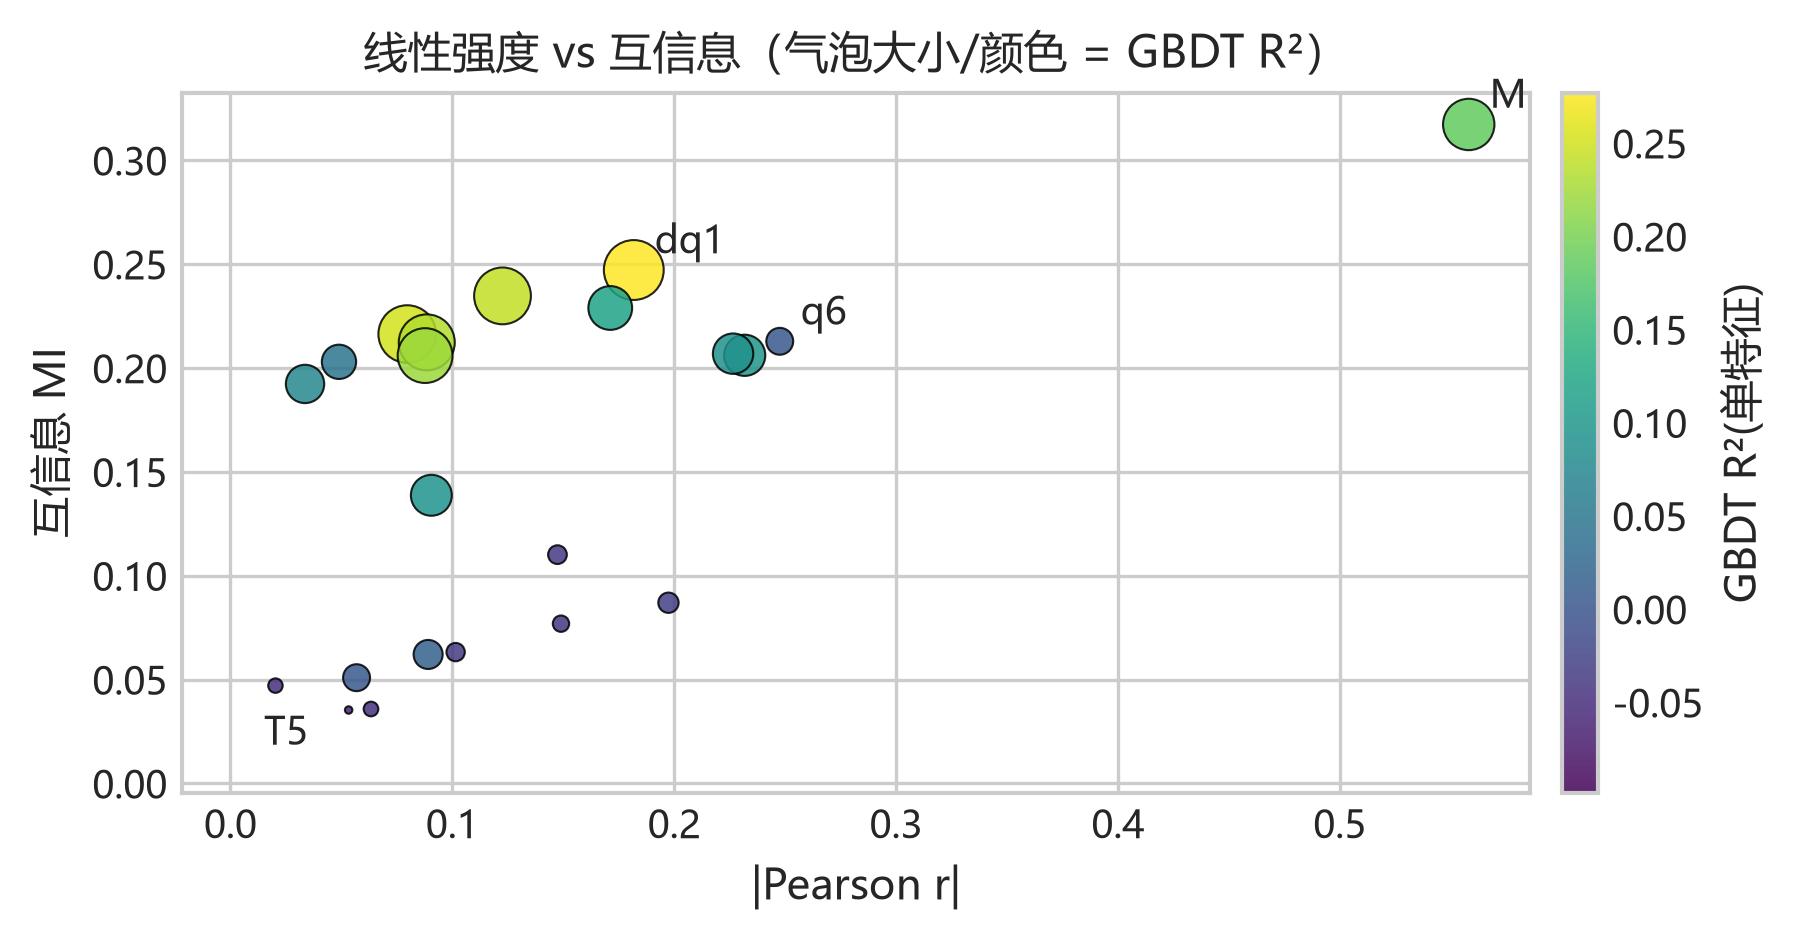

In [10]:
# 线性 vs 非线性指标对比（拆为 3 张单图）
order = nl.index[::-1]

# ---------- 06a |Pearson r| 与距离相关 dCor ----------
# 注意：|r| 画在负半轴只是为了与 dCor 分列显示（便于同轴比较长度），横轴标注已说明
fig, ax = plt.subplots(figsize=fig_size(0.85))
ax.barh(order, -nl.loc[order, "Pearson r"].abs(), color="#9ecae1", label="|Pearson r|（向左）")
ax.barh(order, nl.loc[order, "距离相关dCor"], color="#fdd0a2", alpha=0.85, label="dCor（向右）")
ax.set_xscale("symlog", linthresh=0.1)
ax.set_ylim(-0.6, len(order) + 1.6)          # 顶部留白，图例不与条形重叠
ax.axvline(0, color="k", lw=0.8)
ax.set_title("各特征 |Pearson r| 与距离相关 dCor（dCor 明显更大 → 存在非线性依赖）", fontsize=FS_TITLE)
ax.set_xlabel("向左：|Pearson r|　向右：dCor（symlog 刻度，负向仅用于分列）", fontsize=FS_LABEL)
ax.legend(fontsize=FS_LEGEND, loc="upper left", ncol=2, framealpha=0.9, borderpad=0.3)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "06a_r_vs_dcor")
plt.show()

# ---------- 06b 单特征可解释方差：线性 vs GBDT ----------
yy = np.arange(len(order))
fig, ax = plt.subplots(figsize=fig_size(0.85))
ax.barh(yy - 0.2, nl.loc[order, "线性R²(单特征)"], height=0.4, color="#4C72B0", label="线性 R²")
ax.barh(yy + 0.2, nl.loc[order, "GBDT R²(单特征)"], height=0.4, color="#C44E52", label="GBDT R²")
ax.set_yticks(yy)
ax.set_yticklabels(order, fontsize=FS_TICK)
ax.axvline(0, color="k", lw=0.8)
ax.set_ylim(-0.6, len(order) + 1.6)          # 同样在顶部留白放图例
ax.set_title("单特征可解释方差：线性模型 vs GBDT", fontsize=FS_TITLE)
ax.set_xlabel("验证集 R²", fontsize=FS_LABEL)
ax.legend(fontsize=FS_LEGEND, loc="upper left", ncol=2, framealpha=0.9, borderpad=0.3)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "06b_linear_vs_gbdt_r2")
plt.show()

# ---------- 06c 线性强度 vs 互信息 ----------
fig, ax = plt.subplots(figsize=fig_size(0.52))
sc = ax.scatter(nl["Pearson r"].abs(), nl["互信息MI"], s=40 + 600 * nl["GBDT R²(单特征)"],
                c=nl["GBDT R²(单特征)"], cmap="viridis", alpha=0.85, edgecolor="k", linewidth=0.5)
# 只标注主要特征（GBDT R² 最大者与互信息最高者），避免密集区域文字重叠
lab_set = {"dq1", "q6", nl["Pearson r"].abs().idxmax(), nl["互信息MI"].idxmin()}
for f in nl.index:
    if f in lab_set:
        ax.annotate(f, (abs(nl.loc[f, "Pearson r"]), nl.loc[f, "互信息MI"]), fontsize=FS_TICK,
                    xytext=(5, 4), textcoords="offset points")
ax.set_xlabel("|Pearson r|", fontsize=FS_LABEL)
ax.set_ylabel("互信息 MI", fontsize=FS_LABEL)
ax.set_title("线性强度 vs 互信息（气泡大小/颜色 = GBDT R²）", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
_cb = plt.colorbar(sc, ax=ax, pad=0.02)
_cb.ax.tick_params(labelsize=FS_TICK)
_cb.set_label("GBDT R²(单特征)", fontsize=FS_LABEL)
fig.tight_layout()
savefig(fig, "06c_r_vs_mi")
plt.show()

LightGBM（当前时刻 25 维）                R²=0.7571  RMSE= 5.286 W
最佳迭代轮数: 2010

LightGBM 特征重要性:


,分裂增益 gain,分裂次数 split,增益占比%
dq1,2.022788e+07,4604,22.873
M,1.191795e+07,5172,13.476
q6,9.102016e+06,2538,10.292
dq2,4.776496e+06,5063,5.401
Fa3,4.623788e+06,5432,5.228
q3,4.103250e+06,3238,4.640
dq3,4.069440e+06,3942,4.602
T1,4.017526e+06,7886,4.543
Fa2,3.712647e+06,4829,4.198
q2,3.683183e+06,4134,4.165


[saved] figures\feature_analysis\07a_gain_importance.png  (300 dpi)


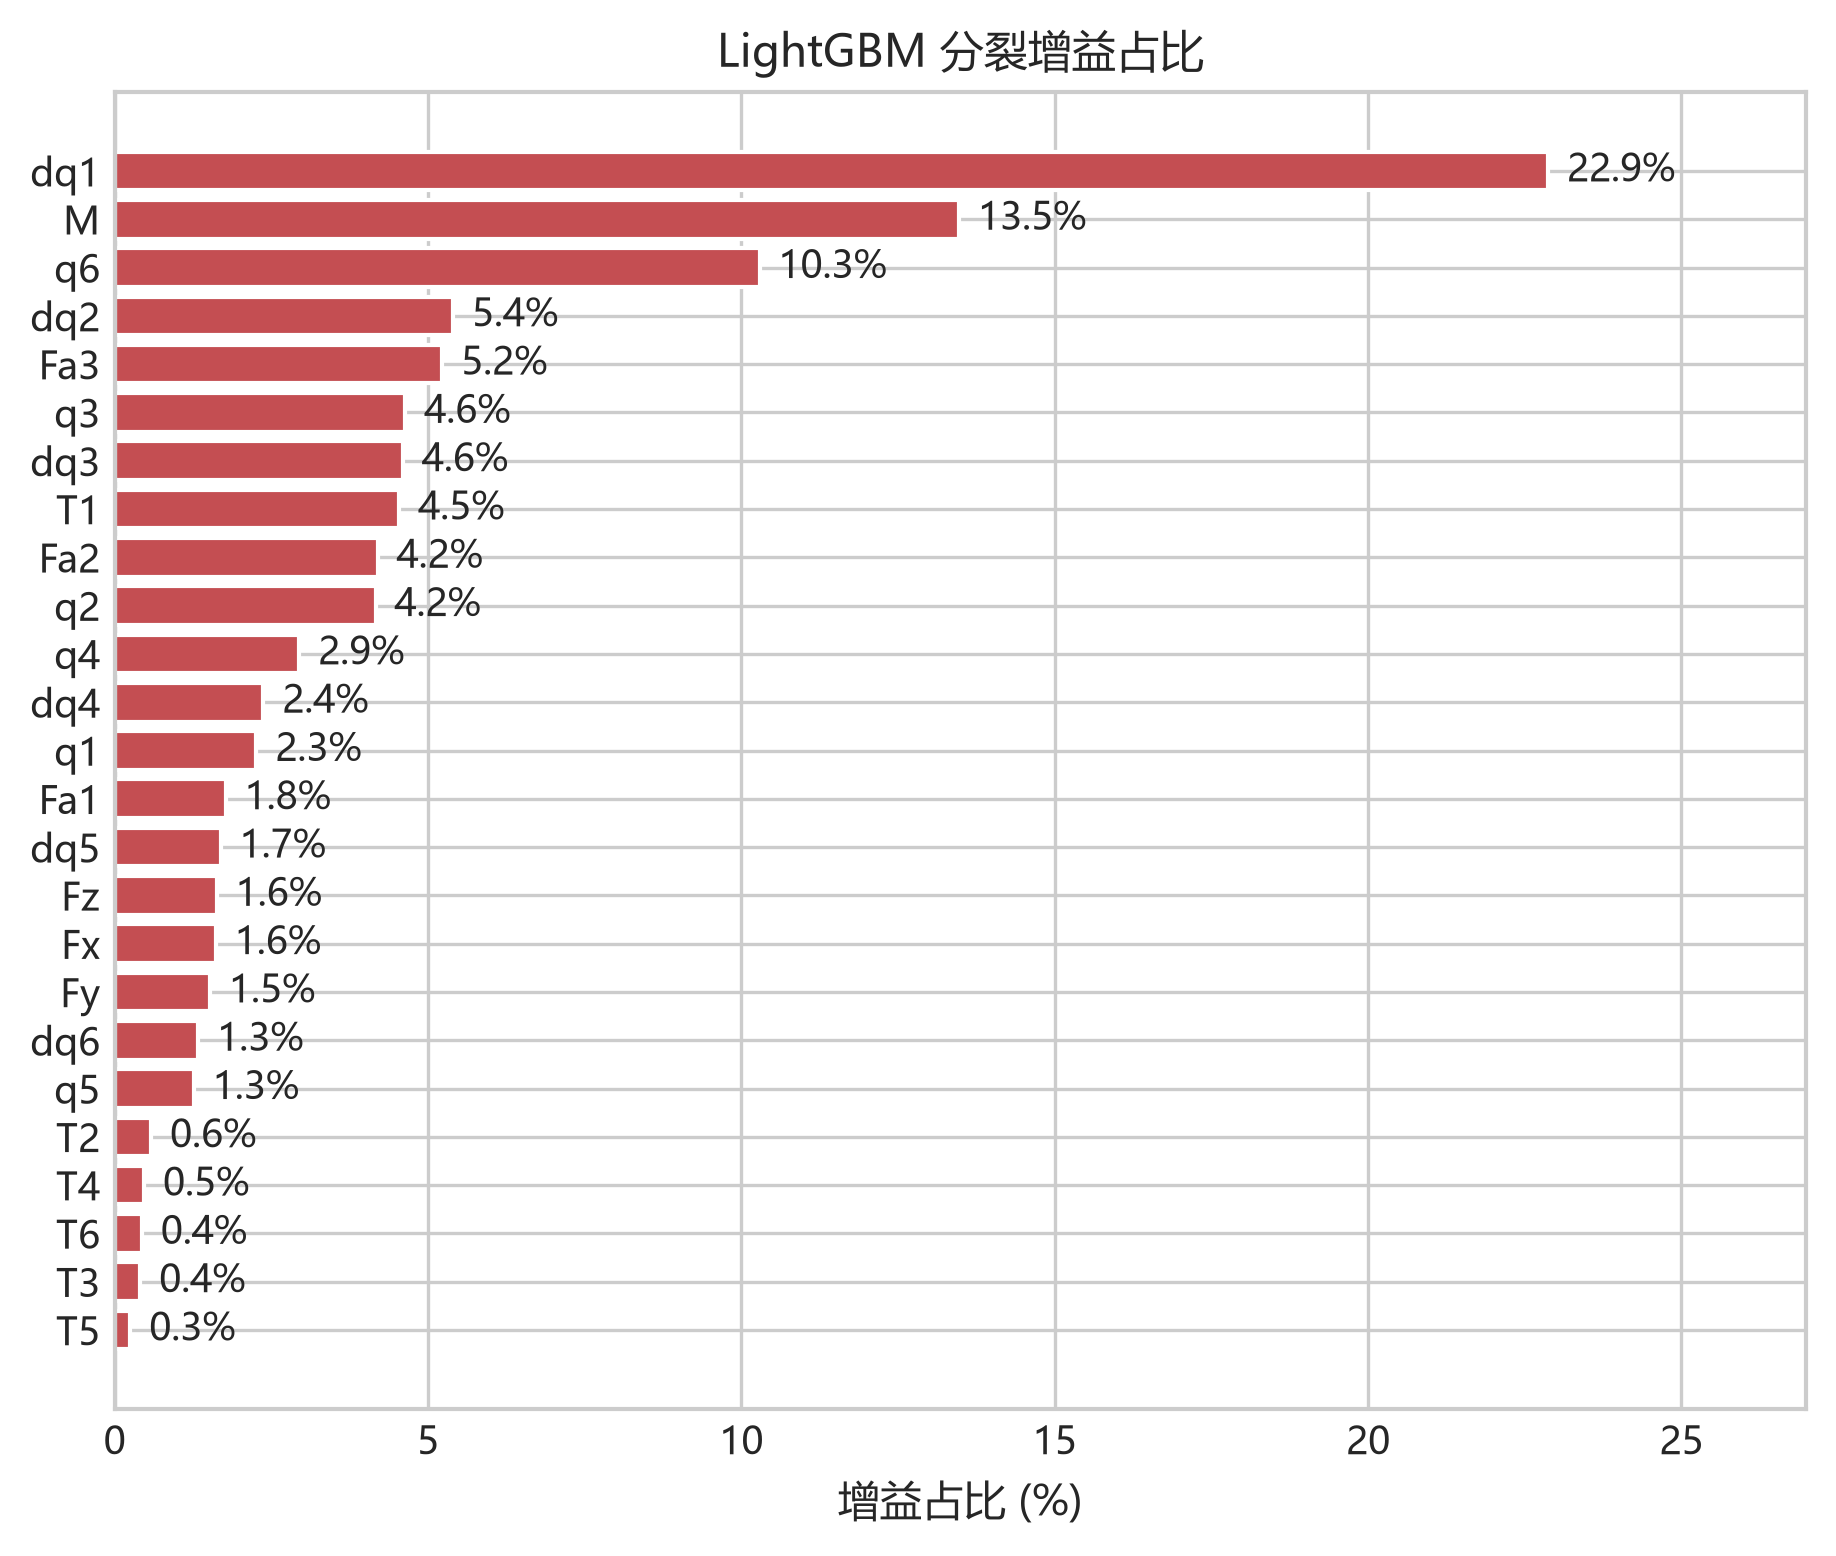

[saved] figures\feature_analysis\07b_gain_vs_linear.png  (300 dpi)


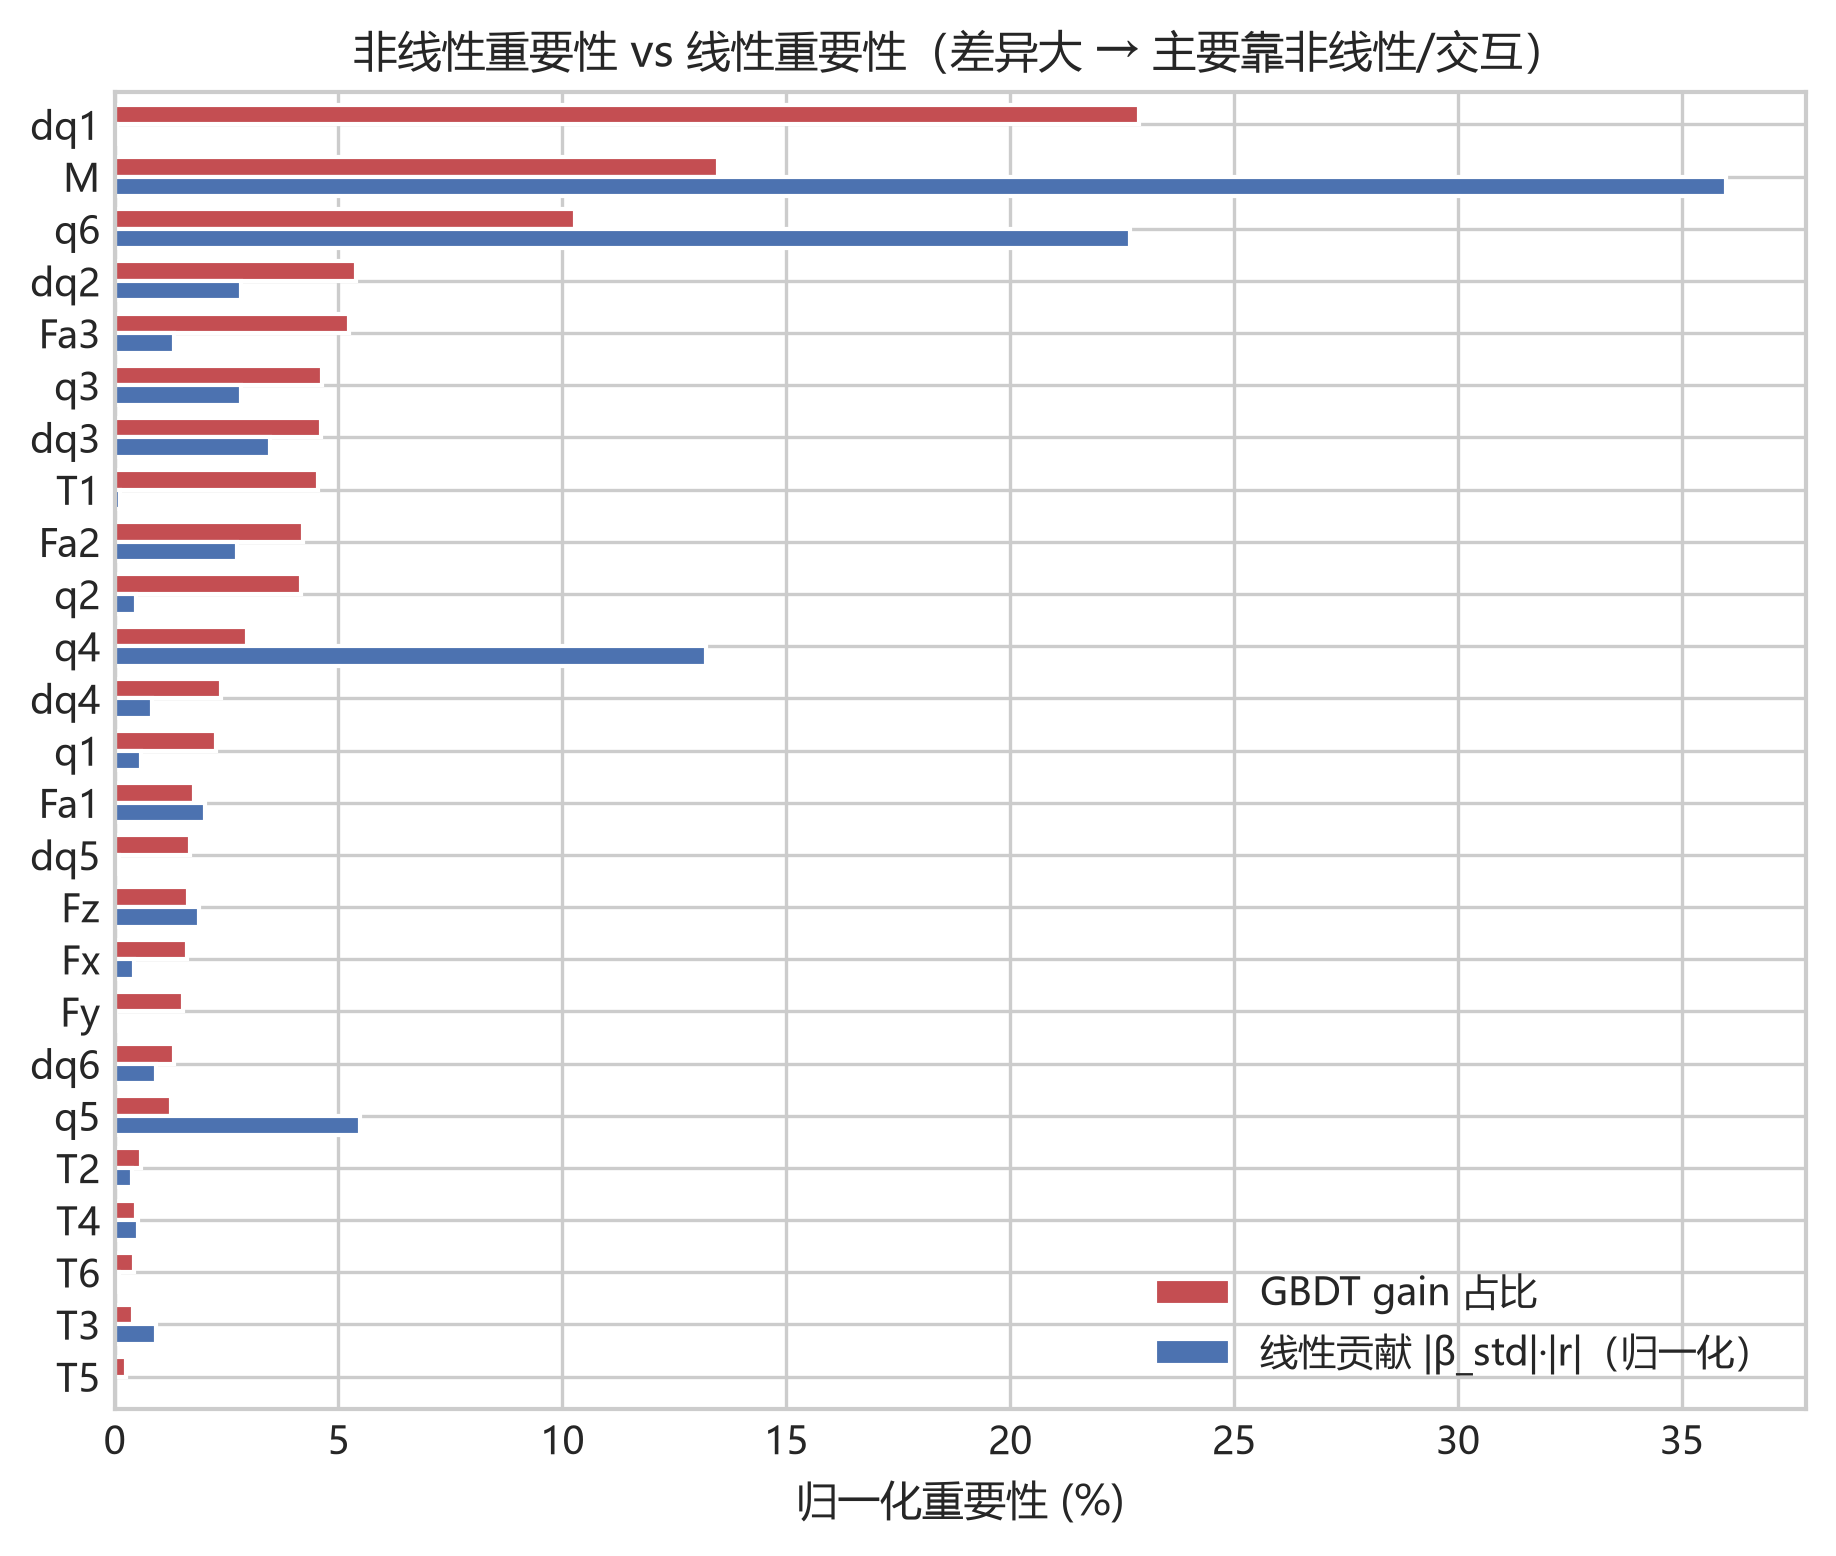

[saved] figures\feature_analysis\08_pdp_top6.png  (300 dpi)


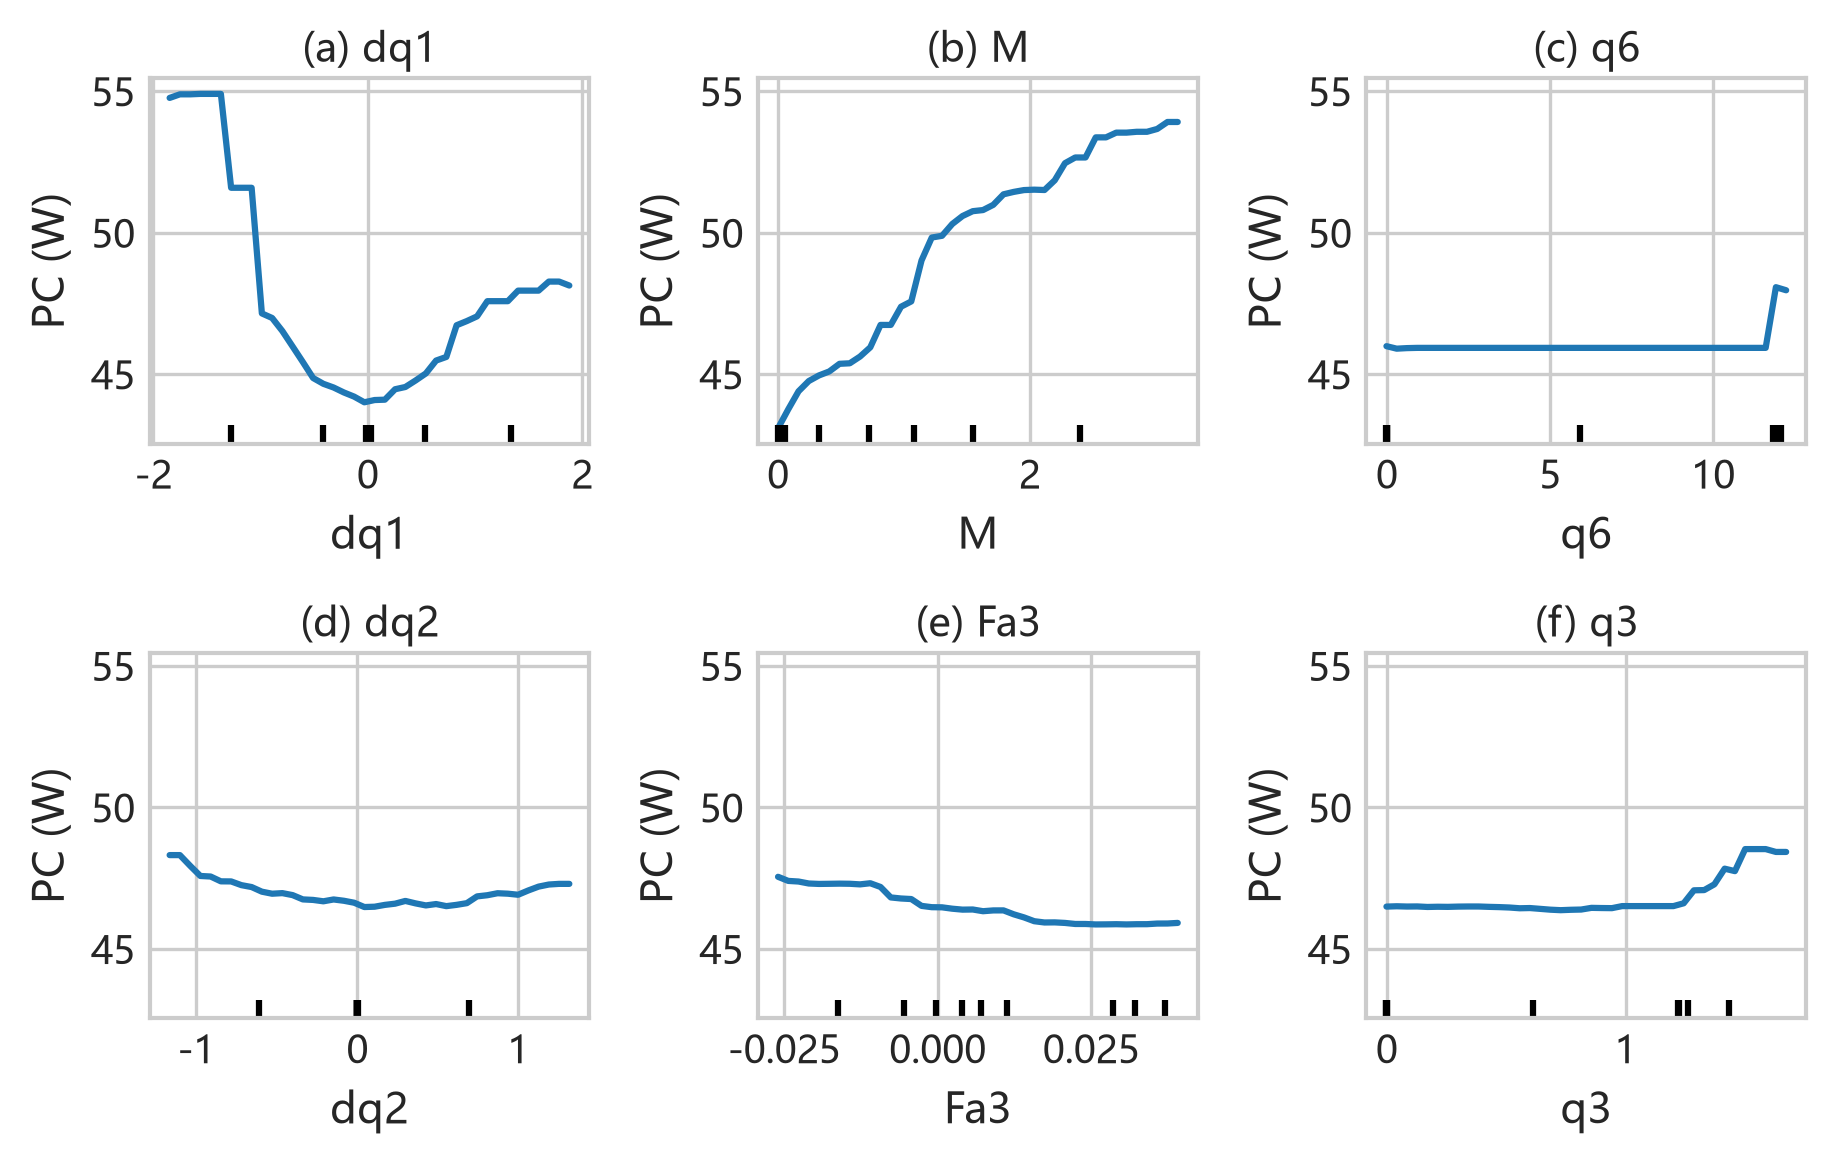

[saved] figures\feature_analysis\09_pdp_2d.png  (300 dpi)


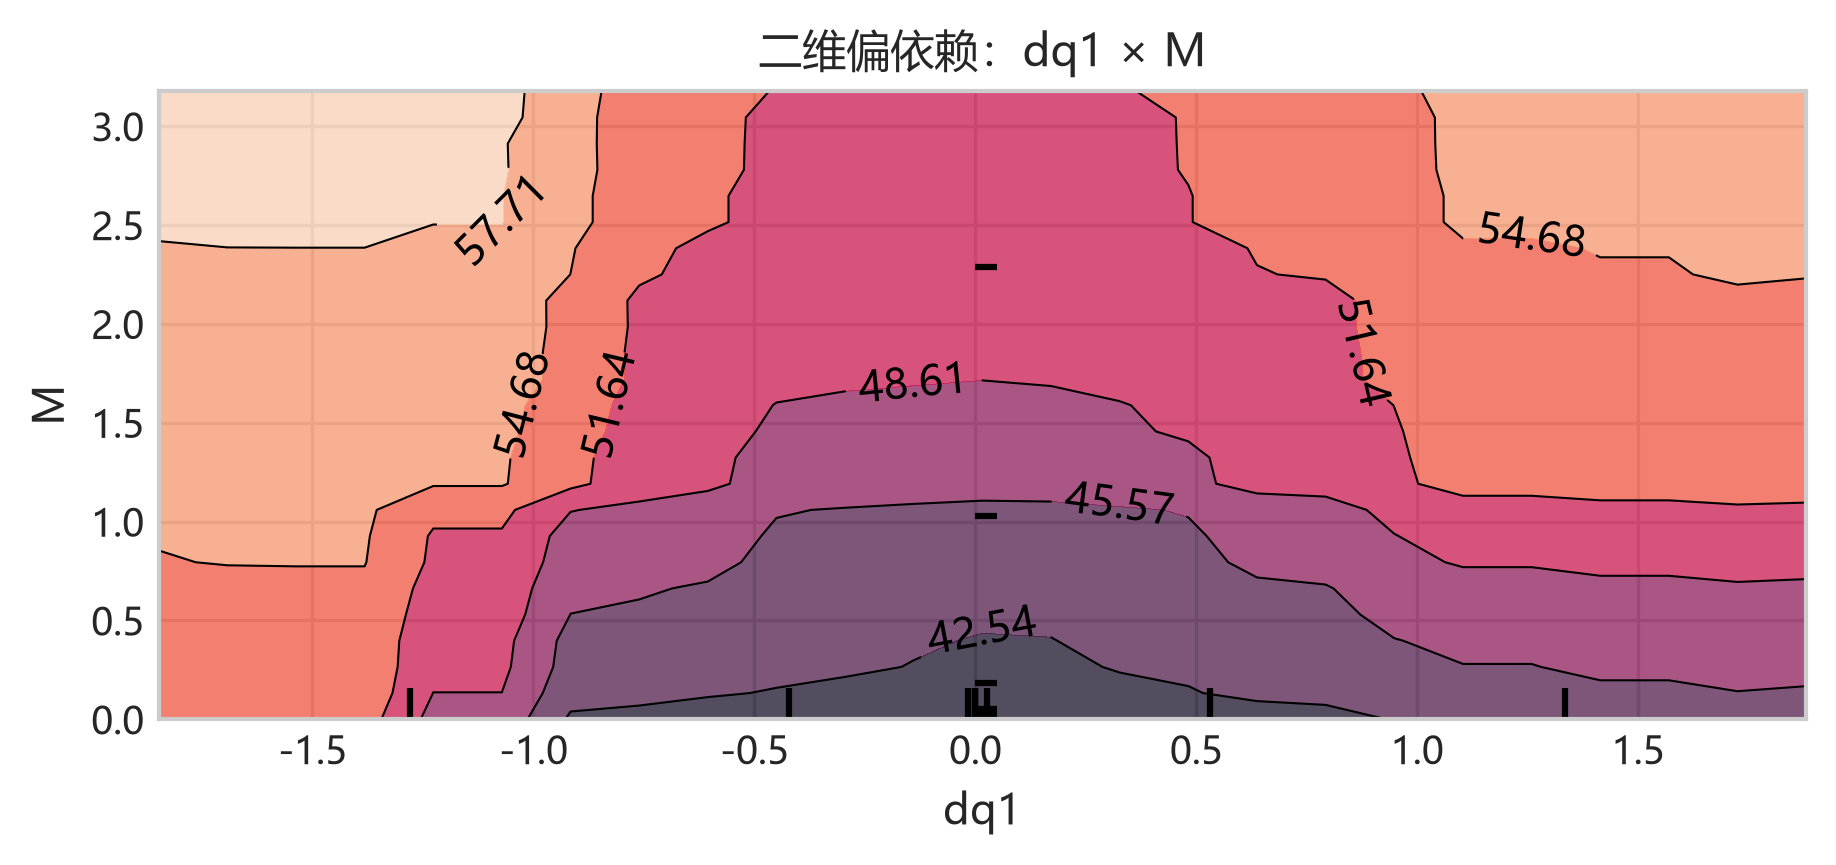

In [11]:
# ============================================================
# 3.3 全特征 GBDT：特征重要性 + 偏依赖（PDP）+ 二维交互
# ============================================================
from sklearn.inspection import PartialDependenceDisplay

gbm_full = lgb.LGBMRegressor(
    n_estimators=3000, learning_rate=0.03, num_leaves=63, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=0, verbose=-1, n_jobs=-1,
)
gbm_full.fit(
    X[tr_m], y[tr_m],
    eval_set=[(X[te_m], y[te_m])], eval_metric="rmse",
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)
pred_gbm = gbm_full.predict(X[te_m])
results.append(report("LightGBM（当前时刻 25 维）", pred_gbm, y[te_m]))
print(f"最佳迭代轮数: {gbm_full.best_iteration_}")

imp = pd.DataFrame({
    "分裂增益 gain": gbm_full.booster_.feature_importance("gain"),
    "分裂次数 split": gbm_full.booster_.feature_importance("split"),
}, index=FEATS)
imp["增益占比%"] = imp["分裂增益 gain"] / imp["分裂增益 gain"].sum() * 100
imp = imp.sort_values("分裂增益 gain", ascending=False)
print("\nLightGBM 特征重要性:")
display(imp.round(3))

# ---------- 07a LightGBM 分裂增益占比 ----------
o = imp.index[::-1]
fig, ax = plt.subplots(figsize=fig_size(0.85))
ax.barh(o, imp.loc[o, "增益占比%"], color="#C44E52")
for i, v in enumerate(imp.loc[o, "增益占比%"]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=FS_TICK)
ax.set_xlim(0, imp["增益占比%"].max() * 1.18)
ax.set_title("LightGBM 分裂增益占比", fontsize=FS_TITLE)
ax.set_xlabel("增益占比 (%)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "07a_gain_importance")
plt.show()

# ---------- 07b 非线性重要性 vs 线性重要性 ----------
compare = pd.DataFrame({
    "GBDT gain 占比": imp["增益占比%"],
    "线性贡献 |β_std|·|r|（归一化）": (coef.abs() * pear.loc[FEATS, TARGET].abs()) /
                                     (coef.abs() * pear.loc[FEATS, TARGET].abs()).sum() * 100,
}).sort_values("GBDT gain 占比", ascending=False)
fig, ax = plt.subplots(figsize=fig_size(0.85))
compare.plot(kind="barh", ax=ax, color=["#C44E52", "#4C72B0"], width=0.75)
ax.invert_yaxis()
ax.set_title("非线性重要性 vs 线性重要性（差异大 → 主要靠非线性/交互）", fontsize=FS_TITLE)
ax.set_xlabel("归一化重要性 (%)", fontsize=FS_LABEL)
ax.legend(fontsize=FS_LEGEND, loc="lower right", framealpha=0.9)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "07b_gain_vs_linear")
plt.show()

# ---------- 08 偏依赖图（前 6 个最重要特征，2×3 排列）----------
top6 = imp.index[:6].tolist()
X_sample = pd.DataFrame(X[te_m][:6000], columns=FEATS)
fig, axes = plt.subplots(2, 3, figsize=fig_size(0.64))
PartialDependenceDisplay.from_estimator(
    gbm_full, X_sample, features=top6, kind="average",
    grid_resolution=40, subsample=0.6, random_state=0,
    ax=list(axes.ravel()), n_jobs=-1,
)
for ax, tag, f in zip(axes.ravel(), "abcdef", top6):
    tag_title(ax, tag, f, fontsize=9.5)
    ax.set_ylabel("PC (W)", fontsize=FS_LABEL)
    ax.set_xlabel(f, fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "08_pdp_top6")
plt.show()

# ---------- 09 二维交互 PDP（单图）----------
f1, f2 = top6[0], top6[1]
fig, ax = plt.subplots(figsize=fig_size(0.48))
PartialDependenceDisplay.from_estimator(
    gbm_full, X_sample, features=[(f1, f2)], kind="average",
    grid_resolution=25, subsample=0.6, random_state=0, ax=ax, n_jobs=-1,
)
ax.set_title(f"二维偏依赖：{f1} × {f2}", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
fig.tight_layout()
savefig(fig, "09_pdp_2d")
plt.show()

## 4. 时延相关性分析

功率是**状态量**，而速度/力/力矩是**驱动量**，二者之间可能存在物理上的响应时延（伺服环带宽、滤波器、采样与通信延迟）—— 这正是"加入历史窗口（L=10/20）是否有必要"的物理前提。本节不预设时延一定存在，而是先检验它在哪个通道、哪个时标上出现，再量化滞后特征带来的实际增益。具体回答：

1. `corr(PC_t, x_{t-k})` 在哪个 `k` 上最强？不同特征的最优时延是多少？
2. 方向性：是"特征领先 PC"（物理因果）还是"PC 领先特征"（反馈/惯性）？
3. 采样率混用（100 Hz / 50 Hz）是否影响结论？
4. 加入滞后特征后，R² 到底能提升多少（这才是时延分析的真正价值）。

> 实现要点：滞后必须在 `trajectory_id` 分组内 `shift`，否则轨迹边界会混入其他轨迹的数据；`lag` 同时给出样本数与秒数，便于跨采样率比较。

100 Hz 子集: 82 条轨迹 / 41000 样本 / 51 个滞后点

各特征的最优滞后（按 |r| 降序；峰位在边界=True 表示需扩大搜索范围）:


,r(lag=0),r(最优|r|),最优lag(样本),最优延迟(s),|r| 提升,峰位在边界
M,0.6165,0.6965,44,0.44,0.0799,False
Fy,-0.3532,-0.4988,9,0.09,0.1456,False
Fa3,-0.4279,-0.4584,4,0.04,0.0305,False
q3,0.4144,0.4448,20,0.20,0.0304,False
Fz,-0.3354,-0.4236,10,0.10,0.0882,False
Fa1,-0.3869,-0.3869,0,0.00,0.0000,False
Fa2,0.3646,0.3832,11,0.11,0.0186,False
q6,0.3683,0.3753,18,0.18,0.0070,False
q5,-0.3590,-0.3609,17,0.17,0.0019,False
q4,-0.3567,-0.3586,50,0.50,0.0019,True


[saved] figures\feature_analysis\10a_lag_heatmap.png  (300 dpi)


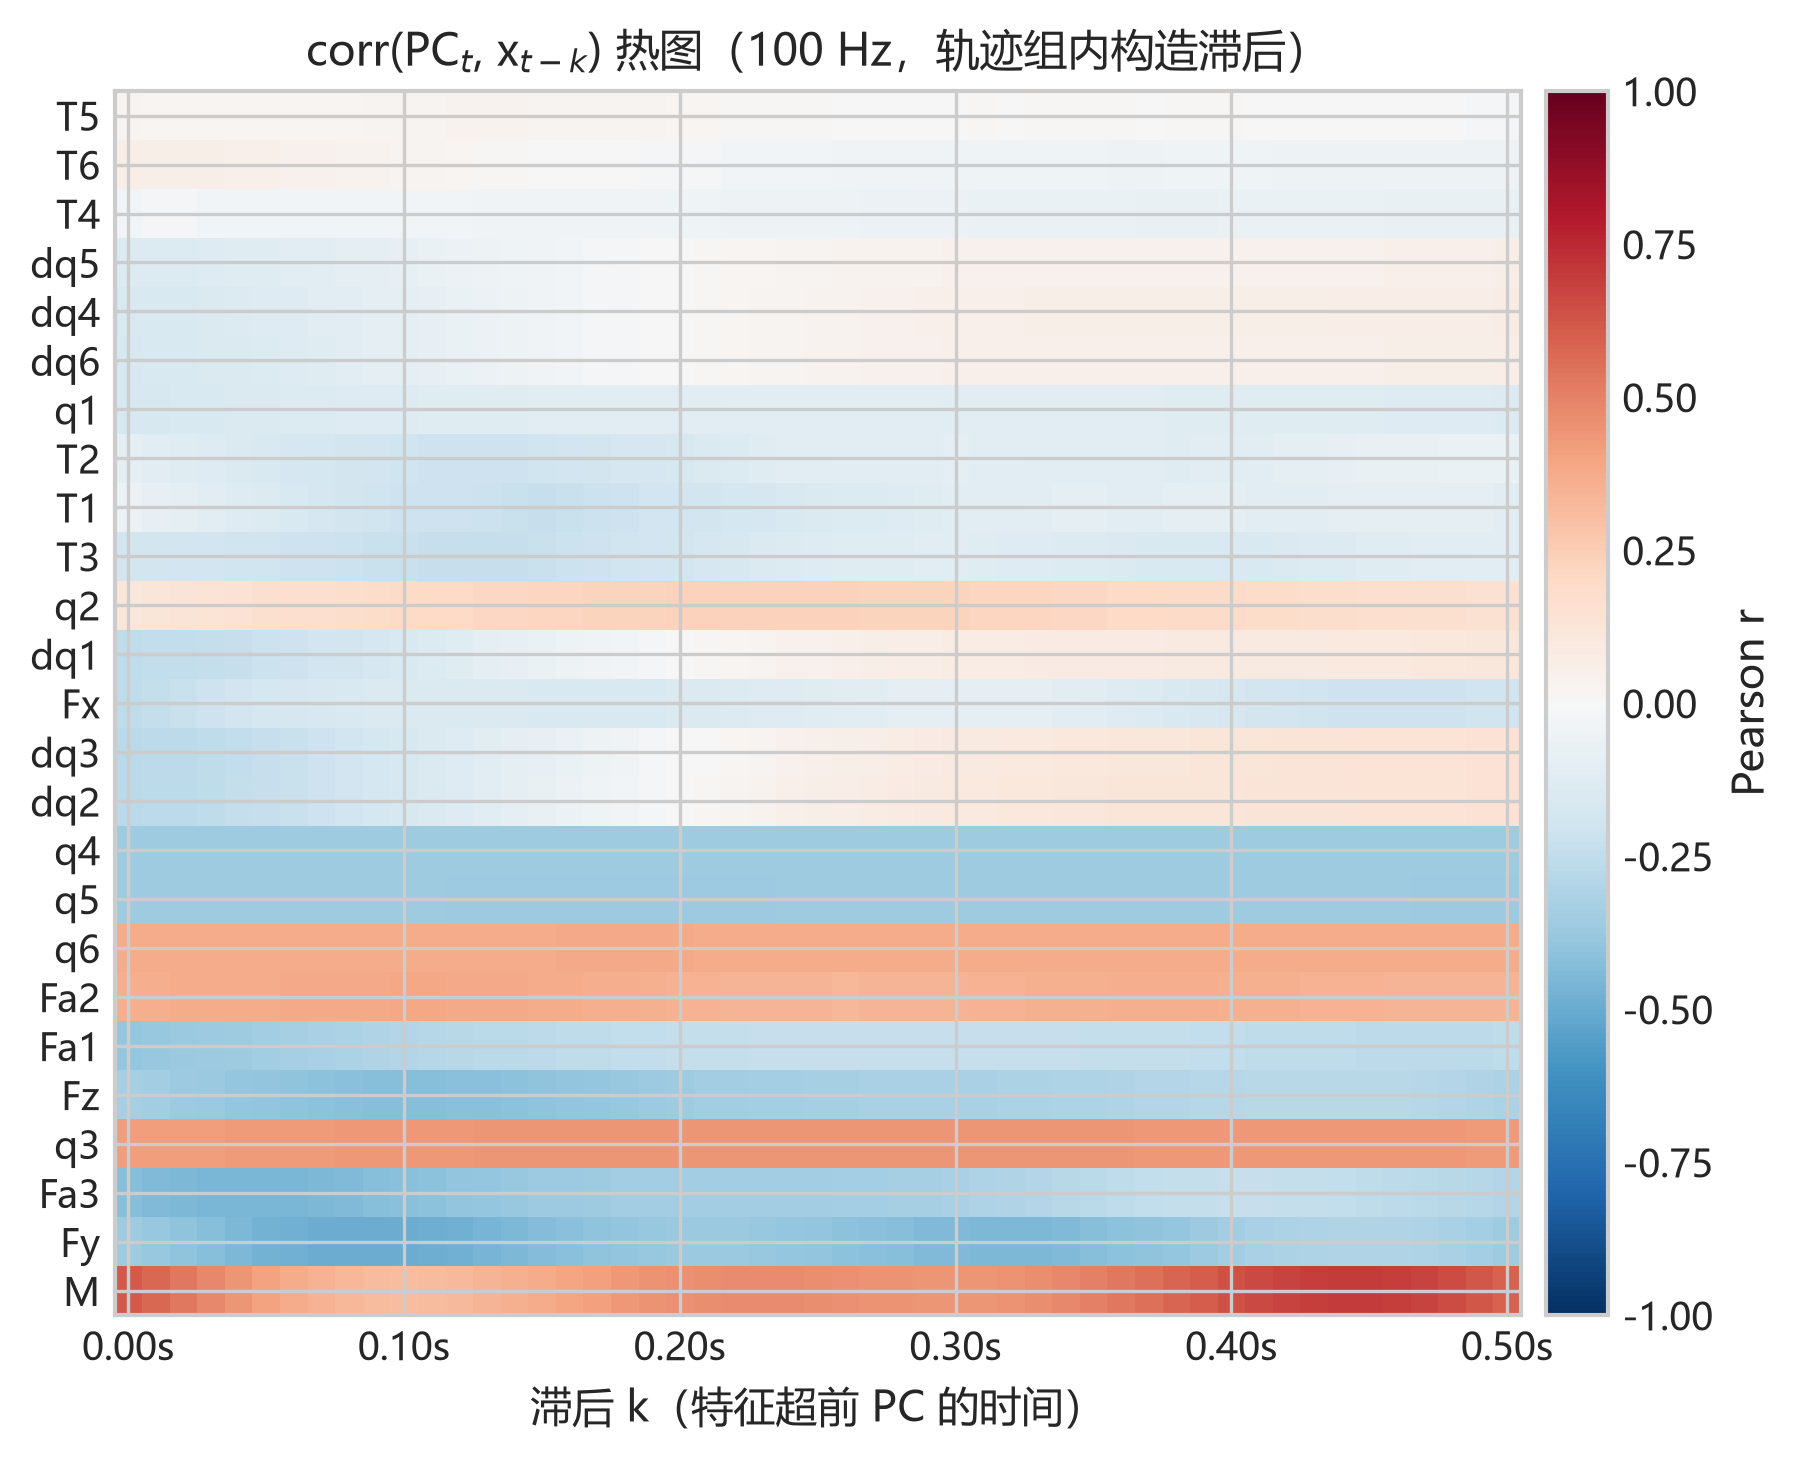

[saved] figures\feature_analysis\10b_delay_gain.png  (300 dpi)


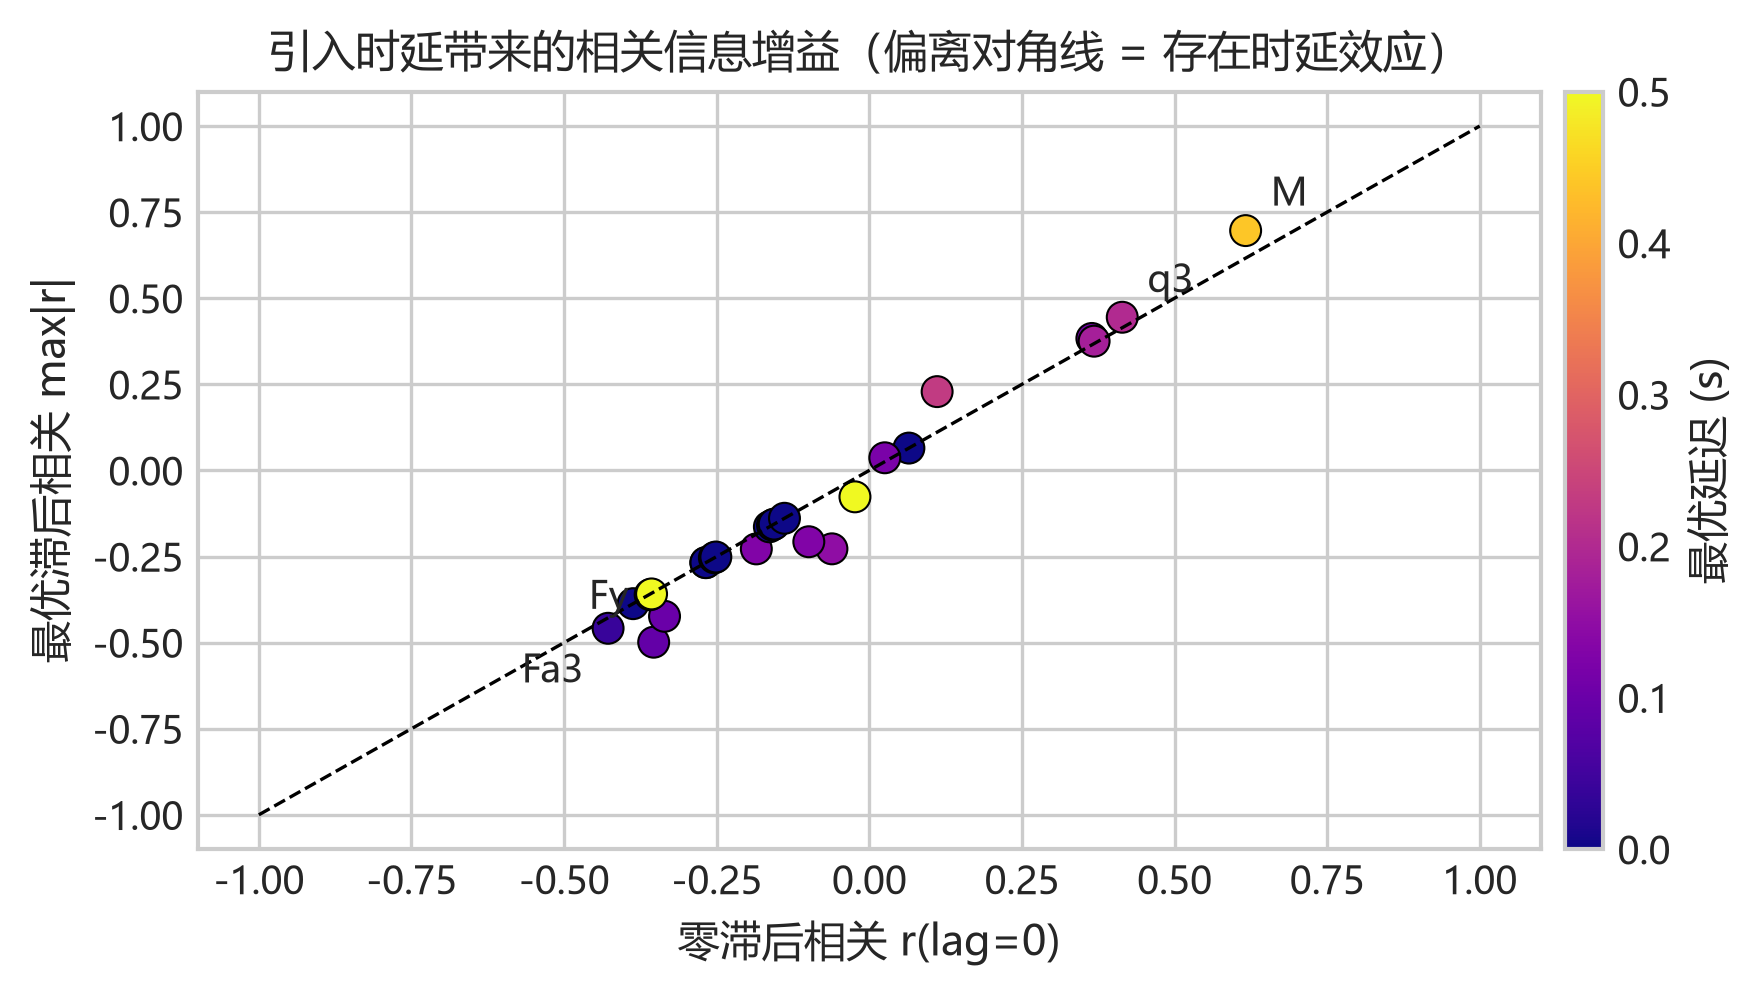

In [12]:
# ============================================================
# 4.1 时延互相关：corr(PC_t, x_{t-k})，只在 100 Hz 轨迹上计算
# ============================================================
# 采样率混合（100/50/2 Hz），时延必须换算成秒；先固定用 100 Hz 子集保证 lag 单位一致
sub = df[df.fs == 100].copy()
DT = 0.01
LAGS = np.arange(0, 51)  # 0 ~ 0.50 s

y100 = sub[TARGET].to_numpy(float)
grp100 = sub.groupby("trajectory_id")

lag_corr = pd.DataFrame(index=FEATS, columns=LAGS, dtype=float)
for c in FEATS:
    g = grp100[c]
    for k in LAGS:
        xk = g.shift(int(k))
        m = xk.notna().to_numpy()
        lag_corr.loc[c, k] = np.corrcoef(xk.to_numpy()[m], y100[m])[0, 1]

print(f"100 Hz 子集: {sub.trajectory_id.nunique()} 条轨迹 / {len(sub)} 样本 / {len(LAGS)} 个滞后点")

# 每个特征的最优滞后（按 |r| 取峰）
k_best = lag_corr.abs().idxmax(axis=1)
r_best = pd.Series([lag_corr.loc[f, k_best[f]] for f in FEATS], index=FEATS)
peak = pd.DataFrame({"r(lag=0)": lag_corr[0], "r(最优|r|)": r_best, "最优lag(样本)": k_best})
peak["最优延迟(s)"] = peak["最优lag(样本)"] * DT
peak["|r| 提升"] = peak["r(最优|r|)"].abs() - peak["r(lag=0)"].abs()
peak["峰位在边界"] = peak["最优lag(样本)"] >= LAGS[-1]
peak = peak.sort_values("r(最优|r|)", key=np.abs, ascending=False)
print("\n各特征的最优滞后（按 |r| 降序；峰位在边界=True 表示需扩大搜索范围）:")
display(peak.round(4))

# ---------- 10a lag × 特征 的相关热图 ----------
fig, ax = plt.subplots(figsize=fig_size(0.80))
o = peak.index[::-1]
im = ax.imshow(lag_corr.loc[o].to_numpy(float), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_yticks(range(len(o)))
ax.set_yticklabels(o, fontsize=FS_TICK)
tick_idx = list(range(0, len(LAGS), 10))
ax.set_xticks(tick_idx)
ax.set_xticklabels([f"{LAGS[i] * DT:.2f}s" for i in tick_idx], fontsize=FS_TICK)
ax.set_xlabel("滞后 k（特征超前 PC 的时间）", fontsize=FS_LABEL)
ax.set_title("corr(PC$_t$, x$_{t-k}$) 热图（100 Hz，轨迹组内构造滞后）", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
_cb = plt.colorbar(im, ax=ax, pad=0.015)
_cb.ax.tick_params(labelsize=FS_TICK)
_cb.set_label("Pearson r", fontsize=FS_LABEL)
fig.tight_layout()
savefig(fig, "10a_lag_heatmap")
plt.show()

# ---------- 10b 时延带来的相关信息增益 ----------
fig, ax = plt.subplots(figsize=fig_size(0.55))
ax.scatter(peak["r(lag=0)"], peak["r(最优|r|)"], c=peak["最优延迟(s)"], cmap="plasma",
           s=55, edgecolor="k", linewidth=0.5)
ax.plot([-1, 1], [-1, 1], "k--", lw=0.8)
_n_neg = 0
for f in peak.index:
    if abs(peak.loc[f, "r(最优|r|)"]) > 0.44:      # 只标注相关最强的几个特征
        v = peak.loc[f, "r(最优|r|)"]
        if v > 0:
            off = (6, 6)
            ha = "left"
        else:                                       # 负相关点标签放左侧，且上下错开避免重叠
            off = (-6, 8 if _n_neg % 2 == 0 else -13)
            ha = "right"
            _n_neg += 1
        ax.annotate(f, (peak.loc[f, "r(lag=0)"], v), fontsize=FS_TICK,
                    xytext=off, textcoords="offset points", ha=ha)
ax.set_xlabel("零滞后相关 r(lag=0)", fontsize=FS_LABEL)
ax.set_ylabel("最优滞后相关 max|r|", fontsize=FS_LABEL)
ax.set_title("引入时延带来的相关信息增益（偏离对角线 = 存在时延效应）", fontsize=FS_TITLE)
ax.tick_params(labelsize=FS_TICK)
_cb2 = plt.colorbar(ax.collections[0], ax=ax, pad=0.015)
_cb2.ax.tick_params(labelsize=FS_TICK)
_cb2.set_label("最优延迟 (s)", fontsize=FS_LABEL)
fig.tight_layout()
savefig(fig, "10b_delay_gain")
plt.show()

[saved] figures\feature_analysis\11_cross_correlation.png  (300 dpi)


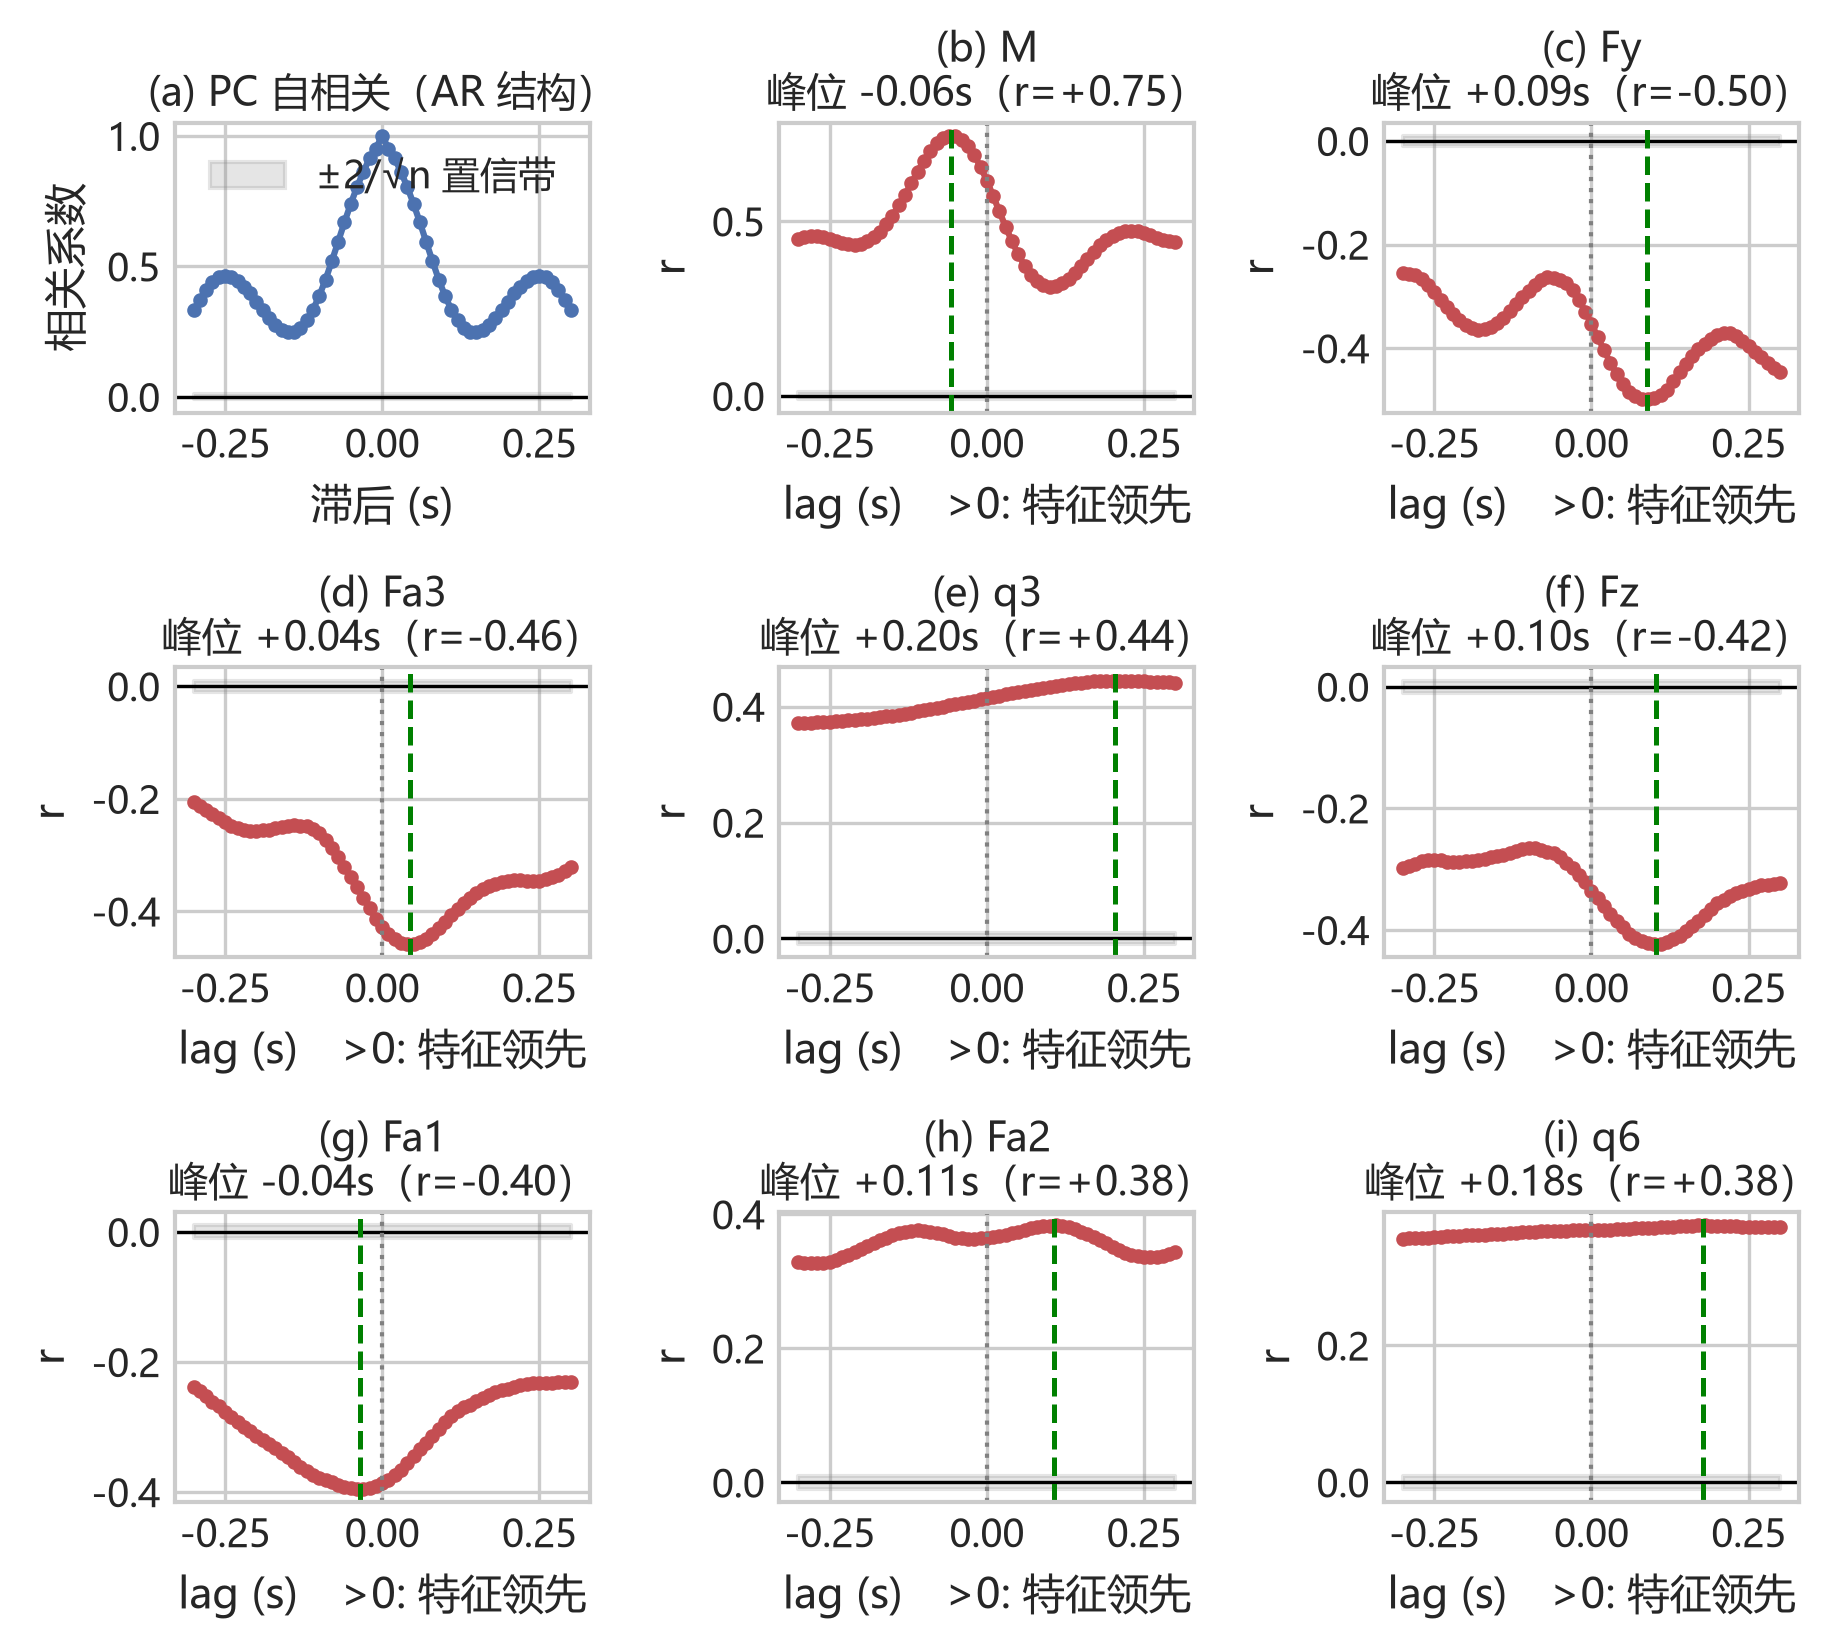

插值细化后的峰值滞后:


,特征,零滞后 r,峰值 r,峰位 lag(样本),峰位延迟(s)
0,M,0.6165,0.7453,-5.6898,-0.0569
1,Fy,-0.3532,-0.4988,8.7994,0.0880
2,Fa3,-0.4279,-0.4586,4.3907,0.0439
3,q3,0.4144,0.4448,20.3884,0.2039
4,Fz,-0.3354,-0.4236,10.1981,0.1020
5,Fa1,-0.3869,-0.3956,-3.5138,-0.0351
6,Fa2,0.3646,0.3833,10.7247,0.1072
7,q6,0.3683,0.3753,17.7646,0.1776



PC 自相关 r(lag=1)=0.9511，r(lag=10)=0.3867，r(lag=20)=0.3650
→ 高自相关说明功率序列强惯性，自回归项（历史 PC）本身就携带大量信息


In [13]:
# ============================================================
# 4.2 双向互相关曲线：正 lag = 特征领先 PC（特征 → PC），负 lag = PC 领先特征
# ============================================================
NEG_LAGS = np.arange(-30, 31)


def xcorr_curve(col):
    g = grp100[col]
    vals = []
    for k in NEG_LAGS:
        xk = g.shift(int(k))
        m = xk.notna().to_numpy()
        vals.append(np.corrcoef(xk.to_numpy()[m], y100[m])[0, 1])
    return np.array(vals)


top8 = peak.index[:8].tolist()
curves = {c: xcorr_curve(c) for c in top8}
acf_pc = xcorr_curve(TARGET)  # PC 自相关
ci = 2.0 / np.sqrt(len(sub))


def parabola_peak(xs, ys):
    """抛物线插值细化峰位置"""
    i = int(np.argmax(np.abs(ys)))
    if i == 0 or i == len(ys) - 1:
        return float(xs[i]), float(ys[i])
    y0, y1, y2 = np.abs(ys[i - 1]), np.abs(ys[i]), np.abs(ys[i + 1])
    denom = (y0 - 2 * y1 + y2)
    delta = 0.5 * (y0 - y2) / denom if denom != 0 else 0.0
    return float(xs[i] + delta), float(np.sign(ys[i]) * (y1 - 0.25 * (y0 - y2) * delta))


fig, axes = plt.subplots(3, 3, figsize=fig_size(0.90))
ax = axes.ravel()[0]
ax.plot(NEG_LAGS * DT, acf_pc, "o-", ms=2.5, color="#4C72B0")
ax.axhline(0, color="k", lw=0.8)
ax.fill_between(NEG_LAGS * DT, -ci, ci, color="gray", alpha=0.2, label="±2/√n 置信带")
tag_title(ax, "a", "PC 自相关（AR 结构）", fontsize=9.5)
ax.set_xlabel("滞后 (s)", fontsize=FS_LABEL)
ax.set_ylabel("相关系数", fontsize=FS_LABEL)
ax.legend(fontsize=FS_LEGEND)
ax.tick_params(labelsize=FS_TICK)

rows = []
for ax, c, tag in zip(axes.ravel()[1:], top8, "bcdefghi"):
    cur = curves[c]
    kpk, rpk = parabola_peak(NEG_LAGS, cur)
    rows.append({"特征": c, "零滞后 r": cur[NEG_LAGS == 0][0],
                 "峰值 r": rpk, "峰位 lag(样本)": kpk, "峰位延迟(s)": kpk * DT})
    ax.plot(NEG_LAGS * DT, cur, "o-", ms=2.5, color="#C44E52")
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(0, color="gray", ls=":", lw=1)
    ax.fill_between(NEG_LAGS * DT, -ci, ci, color="gray", alpha=0.2)
    ax.axvline(kpk * DT, color="green", ls="--", lw=1.2)
    tag_title(ax, tag, f"{c}\n峰位 {kpk * DT:+.2f}s（r={rpk:+.2f}）", fontsize=9.5)
    ax.set_xlabel("lag (s)　>0: 特征领先", fontsize=FS_LABEL)
    ax.set_ylabel("r", fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)

fig.tight_layout()
savefig(fig, "11_cross_correlation")
plt.show()

lag_peak_tbl = pd.DataFrame(rows).sort_values("峰值 r", key=np.abs, ascending=False)
print("插值细化后的峰值滞后:")
display(lag_peak_tbl.round(4))
print(f"\nPC 自相关 r(lag=1)={acf_pc[NEG_LAGS == 1][0]:.4f}，"
      f"r(lag=10)={acf_pc[NEG_LAGS == 10][0]:.4f}，r(lag=20)={acf_pc[NEG_LAGS == 20][0]:.4f}")
print("→ 高自相关说明功率序列强惯性，自回归项（历史 PC）本身就携带大量信息")

In [14]:
# ============================================================
# 4.3 (a) 采样率稳健性：把 100 Hz 抽取成 50 Hz，检查峰位是否保持不变
#     (b) 时延特征对建模的实际价值
# ============================================================
# 原始 50 Hz 记录本身是另一批轨迹（相关结构也不同），先量化这一差异
cmp_sub = pd.DataFrame({
    "100Hz子集 r(lag0)": {c: sub[c].corr(sub[TARGET]) for c in top8},
    "原始50Hz子集 r(lag0)": {c: df.loc[df.fs == 50, c].corr(df.loc[df.fs == 50, TARGET]) for c in top8},
})
print("不同采样率记录的零滞后相关差异（说明 50/100 Hz 属于不同批次任务，不能直接混算时延）:")
display(cmp_sub.round(3))

# 用抽取的方式在同一批轨迹上验证采样率影响
sub_dec = sub[sub.groupby("trajectory_id").cumcount() % 2 == 0].copy()
DTd = 0.02
yd = sub_dec[TARGET].to_numpy(float)
gd = sub_dec.groupby("trajectory_id")

rows = []
for c in top8:
    ks = np.arange(-15, 16)  # ±0.30 s
    vals = []
    for k in ks:
        xk = gd[c].shift(int(k))
        m = xk.notna().to_numpy()
        vals.append(np.corrcoef(xk.to_numpy()[m], yd[m])[0, 1])
    kk, rr = parabola_peak(ks, np.array(vals))
    rows.append({"特征": c,
                 "100 Hz 峰位(s)": lag_peak_tbl.set_index("特征").loc[c, "峰位延迟(s)"],
                 "抽取成 50 Hz 峰位(s)": kk * DTd,
                 "抽取后峰值 r": rr})

robust = pd.DataFrame(rows)
robust["峰位差(s)"] = robust["抽取成 50 Hz 峰位(s)"] - robust["100 Hz 峰位(s)"]
print("\n降采样稳健性（同一批轨迹，峰位按秒比较）:")
display(robust.round(3))

# ---------- (b) 滞后特征对线性模型的增益 ----------
MAXLAG = 6
g100b = sub.groupby("trajectory_id")
lag_cols = {}
for k in range(MAXLAG):
    for c in FEATS:
        lag_cols[f"{c}__lag{k}"] = g100b[c].shift(k)
LAG_df = pd.DataFrame(lag_cols, index=sub.index)
pc_hist = pd.DataFrame({f"PC__lag{k}": g100b["PC"].shift(k) for k in range(1, MAXLAG)},
                       index=sub.index)

ok = LAG_df.notna().all(axis=1).to_numpy()
ids100 = sub.trajectory_id.to_numpy()
tr100 = ok & np.isin(ids100, TR_IDS)
te100 = ok & np.isin(ids100, VAL_IDS)
yt = sub[TARGET].to_numpy(float)
print(f"\n100 Hz 上可用样本: 训练 {tr100.sum()} / 验证 {te100.sum()}")

Xc = LAG_df[[f"{c}__lag0" for c in FEATS]].to_numpy(float)
Xl1 = LAG_df[[f"{c}__lag{k}" for k in (0, 1) for c in FEATS]].to_numpy(float)
Xl6 = LAG_df.to_numpy(float)

lag_results = []
for name, Xm in [("线性: 当前时刻 25 维", Xc),
                 ("线性: +lag1 (50 维)", Xl1),
                 ("线性: lag0~5 (150 维)", Xl6)]:
    mdl = make_pipeline(StandardScaler(), LinearRegression()).fit(Xm[tr100], yt[tr100])
    lag_results.append(report(name, mdl.predict(Xm[te100]), yt[te100]))

gbm_lag = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.05, num_leaves=63,
                            min_child_samples=30, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.8, random_state=0, verbose=-1, n_jobs=-1)
gbm_lag.fit(Xl1[tr100], yt[tr100], eval_set=[(Xl1[te100], yt[te100])], eval_metric="rmse",
            callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
lag_results.append(report("LightGBM: +lag1 (50 维)", gbm_lag.predict(Xl1[te100]), yt[te100]))

print("\n滞后特征带来的增益（基线 = 当前时刻 25 维线性模型）:")
base = lag_results[0]
for r in lag_results[1:]:
    print(f"  {r['model']:<26s} ΔR²={r['R2'] - base['R2']:+.4f}   "
          f"RMSE 下降 {(base['RMSE'] - r['RMSE']) / base['RMSE'] * 100:+.2f}%")

不同采样率记录的零滞后相关差异（说明 50/100 Hz 属于不同批次任务，不能直接混算时延）:


,100Hz子集 r(lag0),原始50Hz子集 r(lag0)
M,0.617,0.500
Fy,-0.353,0.031
Fa3,-0.428,0.053
q3,0.414,-0.100
Fz,-0.335,-0.092
Fa1,-0.387,-0.081
Fa2,0.365,0.021
q6,0.368,-0.088



降采样稳健性（同一批轨迹，峰位按秒比较）:


,特征,100 Hz 峰位(s),抽取成 50 Hz 峰位(s),抽取后峰值 r,峰位差(s)
0,M,-0.057,-0.058,0.744,-0.001
1,Fy,0.088,0.086,-0.500,-0.002
2,Fa3,0.044,0.042,-0.459,-0.002
3,q3,0.204,0.203,0.444,-0.001
4,Fz,0.102,0.102,-0.426,-0.000
5,Fa1,-0.035,-0.042,-0.400,-0.007
6,Fa2,0.107,0.116,0.381,0.009
7,q6,0.178,0.182,0.374,0.005



100 Hz 上可用样本: 训练 32670 / 验证 7920
线性: 当前时刻 25 维                      R²=0.4892  RMSE= 9.947 W
线性: +lag1 (50 维)                   R²=0.7328  RMSE= 7.195 W
线性: lag0~5 (150 维)                 R²=0.7727  RMSE= 6.635 W
LightGBM: +lag1 (50 维)             R²=0.8150  RMSE= 5.987 W

滞后特征带来的增益（基线 = 当前时刻 25 维线性模型）:
  线性: +lag1 (50 维)           ΔR²=+0.2436   RMSE 下降 +27.67%
  线性: lag0~5 (150 维)         ΔR²=+0.2835   RMSE 下降 +33.30%
  LightGBM: +lag1 (50 维)     ΔR²=+0.3258   RMSE 下降 +39.82%


## 5. 结论汇总

### 5.1 单变量分布
- 数据完整：116 条轨迹 / 105,400 样本，**无缺失、无重复**；采样率混合（82 条 100 Hz、32 条 50 Hz、2 条约 2 Hz），每条轨迹 200–2000 点（5–100 s）。
- 输出 `PC`：均值 44.15 W、标准差 9.41 W、中位数 41.84 W，**右偏（偏度 3.29）+ 尖峰（超峰度 17.8）**；`PC < 0` 仅 0.014%（能量回馈），`PC > 100 W` 占 0.394%，构成长尾。
- 输出方差分解：**轨迹间方差占 36.2%（ICC = 0.362）**，组内去均值后标准差仍有 7.52 W —— 功率差异主要出现在**同一条轨迹的运动过程内部**，而非任务之间。因此按轨迹划分训练/验证是合理的，同时也意味着模型必须能解释轨迹内的动态变化。
- 输入特征：`dq1–dq6` 零值比例 14.8%–26.3%（静止段堆积，超峰度 1.5–7.1，重尾）；`q4/q5/q6` 各有 16.1% 的 1.5×IQR 离群点（来自特定批次的极端姿态）；`V` 变异系数仅 0.049%，`corr(PC, I) = 0.999998` —— **功率分析等价于电流分析**。

### 5.2 线性相关性
- 线性相关整体很弱：只有 `M` 的 |r| 超过 0.5（0.558），其余 24 个特征全部 < 0.25，其中 13 个 < 0.1。
- Pearson 与 Spearman **符号常常相反**（`q6`: 0.248 vs −0.065；`q3`: 0.171 vs −0.003；`q5`: −0.232 vs −0.045）。这与 `q4/q5/q6` 各有 16.1% 的极端姿态样本相吻合（`q6` 最大值 12.46 rad，直方图呈"主体 + 远端尖峰"的双峰形态）：Pearson 主要被这簇离群点拉动，Spearman 反映的是主体样本的秩排序。因此更准确的描述是**双峰 / 非线性**关系，"单调线性"并不成立；线性模型使用前应先处理或单独评估该样本簇。
- 共线性集中在腕部：`q4–q6`（r = −0.972）、`q5–q6`（−0.957）、`q4–q5`（0.913）；VIF：`q4` = 138、`q6` = 121、`q5` = 19.3、`q3` = 16.1。做线性/可解释模型时应合并或剔除其中一个，树模型不受影响。
- 线性回归基线（当前时刻 25 维，按轨迹 8:2 划分）：**R² = 0.398，RMSE = 8.32 W**（均值基准 RMSE 10.72 W）；残差呈扇形（异方差），且在 `PC > 80 W` 处系统性低估 —— 静态线性模型不足以支撑该任务。

### 5.3 非线性关系
- **速度类特征以 `dq1` 的 U 型最典型（左右不对称）**：`dq1` 的 PDP 在 ≈0 处最低（44 W），增到 −2 rad/s 时升至 ≈55 W、增到 +2 rad/s 只回到 ≈48 W（摩擦/铜损给出绝对值效应）。这种不对称并非直接来自重力项 —— 重力项依赖姿态而非速度符号 —— 而是正/负向速度出现在不同姿态与轨迹上（`dq1` 与 `q2/q3` 相关），PDP 边缘化后被姿态混杂所致。`dq1` 的单特征 GBDT R² = 0.277，而线性 R² = −0.05（比均值模型还差），**ΔR² ≈ 0.33**；`dq4–dq6` 的 PDP 幅度不足 1 W（近乎平坦），却仍有 0.22–0.25 的单特征 GBDT R²，说明其作用主要体现在与其它特征的组合上，而非单变量的边缘形状。
- `M` 与功率近似单调递增（M: 0 → 3.2 时 PDP 由 42.5 W 升到 53.8 W），线性模型已能捕捉（单特征线性 R² = 0.308 高于 GBDT 的 0.187），属"线性特征"。
- 量化对比：平均非线性增益 ΔR² = 0.094；互信息与 |Pearson r| 的秩相关仅 0.634，说明**线性指标排不出非线性的强弱次序**（如 `dq4` 的 |r| 只有 0.080，MI 却有 0.216）；距离相关 dCor 普遍远高于 |r|（`dq1`：0.388 vs 0.182）。
- **表格读数注意**：`dq2` 的二次多项式 R² = −0.44、单特征 GBDT R² = −0.10，是**轨迹级分布偏移导致的外推**（验证集 57/83 号轨迹的 `dq2` 达 ±2.33，而训练集最大只到 ±1.88、99.9% 分位 1.61），不能据此认为"`dq2` 非线性弱"——其 MI 0.244、dCor 0.367 都很高，在全模型中的增益占比也有 5.4%。
- 全特征 GBDT（当前时刻）：**R² = 0.757，RMSE = 5.29 W**，相对线性模型 R² 提升 0.36。
- 重要性排序：`dq1` 22.9% > `M` 13.5% > `q6` 10.3% > `dq2` 5.4% > `Fa3` 5.2% > `q3` 4.6% ≈ `dq3` 4.6% > `T1` 4.5%。**按类别：速度类 38.3%、位置类 25.6%、末端力/力矩 16.0%、关节力矩 6.7%、动量 13.5%**。
- 二维 PDP（`dq1 × M`）显示的是**次可加（饱和）型交互**，而非相乘或简单叠加：最低点（`dq1 ≈ 0`、`M ≈ 0`）为 42.5 W；单独把 `dq1` 推到 −1.8 rad/s 或把 `M` 推到 3.2，PDP 各升约 11–12 W；但两者同时拉满最高只到 57.7 W（+15 W），明显低于线性叠加的约 66 W，说明速度与动量之间携带大量冗余信息。峰值区位于 `M ≈ 2.6–3.2`、`|dq1| ≲ 1.2 rad/s` 一带；`|dq1|` 继续增大到 1.5–2 rad/s 时二维 PDP 反而回落到约 51–55 W，即高速段边际收益已饱和 —— 峰值并不在速度最大处。

### 5.4 时延相关性
- 100 Hz 子集（82 条轨迹 / 41,000 样本），按轨迹分组构造 lag：
  - **速度 `dq1–dq6` 峰位在 lag = 0**：速度对功率是**即时**影响，只是关系为 U 型而非线性。
  - **力/力矩存在 0.04–0.11 s 的时延**：`Fa3` 0.044 s（r = −0.459）、`Fy` 0.088 s（−0.499）、`Fz` 0.102 s（−0.424）、`Fa2` 0.107 s（0.383），即**力信号领先功率约 40–110 ms**，符合伺服环 + 滤波器的响应链（`Fa1` 例外，峰位 −0.035 s，功率略领先）。
  - **位置 `q3/q6` 峰位较晚**（0.204 s / 0.178 s），本质是"位置 → 速度 → 力矩"的积分链条造成的间接效应。
  - `M` 零滞后相关最强（0.617），峰位 −0.057 s、峰值 r = 0.745（**功率领先动量**，动量是惯性响应结果）；在特征领先一侧，|r| 随滞后单调升至 0.697（0.44 s），源于两者的共同低频趋势，不应作为物理时延解读。
- **PC 自相关极强**：r(1) = 0.951、r(10) = 0.387、r(20) = 0.365 —— 历史功率本身就是最强信息源，这解释了窗口模型 / ARIMAX 明显优于逐点回归。
- **采样率稳健性**：把 100 Hz 抽取到 50 Hz 后各特征峰位差异 ≤ 0.01 s，结论不受采样率影响。但原始 50 Hz 记录属于**另一批任务**（如 `Fy` 相关 0.03，而 100 Hz 子集为 −0.35），时延分析不应把两批数据混算。
- **建模增益（100 Hz 验证集，按轨迹划分）**：

| 模型 | R² | RMSE (W) | 相对基线 RMSE 下降 |
|---|---|---|---|
| 线性：当前时刻 25 维 | 0.489 | 9.95 | — |
| 线性：+lag1（50 维） | 0.733 | 7.20 | 27.7% |
| 线性：lag0~5（150 维） | 0.773 | 6.64 | 33.3% |
| LightGBM：+lag1（50 维） | 0.815 | 5.99 | 39.8% |

> 该表的基线 0.489 与 5.2 的 0.398 不同，是因为这里只保留 100 Hz 子集（训练 32,670 / 验证 7,920 样本），与全量验证集（22,000 样本）不可直接比较。

### 5.5 对建模的直接启示
1. **必须使用时间窗口**：只看当前时刻的静态特征时，全量验证集上线性回归只能解释 40%（R² = 0.398）、GBDT 76%（R² = 0.757）。在 100 Hz 子集上（该子集的 25 维线性基线为 R² = 0.489），加入 lag1 后线性 R² 升到 0.733、LightGBM 达到 0.815。注意这两组数字分属不同的验证集，GBDT 的 0.757 → 0.815 同时包含"换子集"和"加滞后"两个变化，不能直接当作滞后特征的净增益；净增益应在同一子集内比较（线性 0.489 → 0.733）。
2. **1 步滞后就回收了大部分信息**（线性 R² 0.489 → 0.733），扩到 6 步（0–50 ms）仅再增 0.04（0.773）——增益主要来自功率自相关（r(1) = 0.951），而非特征时延本身；若要显式覆盖力通道 40–110 ms 的时延，滞后窗需 ≥11 步，这与主实验取 $L=20$（200 ms）的经验一致。
3. **特征工程**：显式加入 `|dq_i|`、`dq_i²`、`|dq_i|·M` 等项，可让线性/可解释模型逼近树模型；对力/力矩特征做 4–10 步移位（0.04–0.10 s）。
4. **共线性处理**：`q4/q5/q6` 近共线，线性模型需去冗余；树模型与神经网络可直接使用。
5. **评估注意**：`PC` 重尾（>100 W 尖峰）且 ICC = 0.36，除 RMSE/R² 外应单独报告高功率段与极端轨迹（10/18/11/9 号，峰值 135.6–142.5 W）的误差，避免均值指标掩盖峰值低估。